## K-Means Clustering sur familles de descripteurs

### Import des bibliothèques

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import warnings
warnings.filterwarnings('ignore')

# Configuration matplotlib
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (14, 8)

### Charger dataset

In [2]:
# Charger les données nettoyées
X_train = pd.read_csv('Données/X_train_clean.csv')
print(f'Shape du dataset: {X_train.shape}')
print(f'\nPremières lignes:')
print(X_train.head(3))

Shape du dataset: (444, 34)

Premières lignes:
   Family_Size  PPI_Intersection  PPI_Union  PPI_Jaccard  Pfam_Inter  \
0            4               1.0        9.0    11.111111         1.0   
1            4               1.0       14.0     7.142857         1.0   
2            2              12.0       32.0    37.500000         1.0   

   Pfam_Union  Pfam_Jaccard      Ks      Ka     Ka_Ks  ...  \
0         1.0           1.0  1.8192  0.4049  0.222570  ...   
1         1.0           1.0  1.9732  0.4109  0.208240  ...   
2         1.0           1.0  2.3106  0.5092  0.220376  ...   

   Expression_Data_Missing  TE_Env_Pair_TE-free_TE-free  \
0                        0                         True   
1                        0                        False   
2                        0                         True   

   TE_Env_Pair_TE-free_TE-poor  TE_Env_Pair_TE-free_TE-rich  \
0                        False                        False   
1                        False                      

In [3]:
# Vérification des données
print(f'\nValeurs manquantes:\n{X_train.isnull().sum().sum()} valeurs manquantes au total')
print(f'\nTypes des colonnes:\n{X_train.dtypes.value_counts()}')


Valeurs manquantes:
0 valeurs manquantes au total

Types des colonnes:
float64    22
bool        9
int64       3
Name: count, dtype: int64


### Preprocessing

In [4]:
# Récupérer les variables numériques et les stocker dans une liste
num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns
X_num = X_train[num_cols]

numeric_cols = X_num.columns.tolist()
print(f"Colonnes numériques : {numeric_cols}")

Colonnes numériques : ['Family_Size', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance', 'TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean', 'Pfam_Asymmetry', 'Pfam_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match', 'Expression_Data_Missing']


In [5]:
# Grouper les variables numériques en catégories selon leur nature
descriptor_families = {
    'PPI': ['PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean'],
    'Pfam': ['Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Pfam_Asymmetry', 'Pfam_Mean', 'Family_Size'],
    'Ks_et_Ka': ['Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Expression_Data_Missing', 'Distance'],
    'TE': ['TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 
           'TE_Number_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match'],}


# Filtrer les familles vides
descriptor_families = {k: v for k, v in descriptor_families.items() if len(v) > 0}

print("Familles de descripteurs identifiées:")
for family, cols in descriptor_families.items():
    print(f"  {family}: {len(cols)} colonnes - {cols[:2]}{'...' if len(cols) > 2 else ''}")

# Standardiser les données
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_num),
    columns=X_num.columns
)

Familles de descripteurs identifiées:
  PPI: 5 colonnes - ['PPI_Intersection', 'PPI_Union']...
  Pfam: 6 colonnes - ['Pfam_Inter', 'Pfam_Union']...
  Ks_et_Ka: 7 colonnes - ['Ks', 'Ka']...
  TE: 7 colonnes - ['TE_Coverage_Asymmetry', 'TE_Coverage_Mean']...


## K-means sans t-SNE sur familles descripteurs

In [6]:
# Paramètres K-means
k_values = [2, 3, 4, 5, 7, 9, 10]  # Tester k = 2, 3, 4, 5, 7, 9, 10
n_init = 20
random_state = 42

# Stocker les résultats pour chaque famille de descripteurs
kmeans_results_original = {}

print("Exécution du K-means sur chaque famille de descripteurs...")
print("-" * 70)

for family_name, cols in descriptor_families.items():
    X_family = X_scaled[cols]
    
    # Dictionnaire pour stocker les métriques pour cette famille
    family_results = {
        'inertia': [],
        'silhouette': [],
        'davies_bouldin': [],
        'calinski_harabasz': [],
        'models': [],
        'labels': []
    }
    
    for k in k_values:
        kmeans = KMeans(n_clusters=k, n_init=n_init, random_state=random_state, init='k-means++')
        labels = kmeans.fit_predict(X_family)
        family_results['labels'].append(labels)

        # Calculer les métriques
        inertia = kmeans.inertia_
        silhouette = silhouette_score(X_family, labels) if len(np.unique(labels)) > 1 else np.nan
        davies_bouldin = davies_bouldin_score(X_family, labels) if len(np.unique(labels)) > 1 else np.nan
        calinski_harabasz = calinski_harabasz_score(X_family, labels) if len(np.unique(labels)) > 1 else np.nan
        
        family_results['inertia'].append(inertia)
        family_results['silhouette'].append(silhouette)
        family_results['davies_bouldin'].append(davies_bouldin)
        family_results['calinski_harabasz'].append(calinski_harabasz)
        family_results['models'].append(kmeans)
    
    kmeans_results_original[family_name] = family_results
    print(f"{family_name}: {len(cols)} descripteurs testés")

print("-" * 70)

Exécution du K-means sur chaque famille de descripteurs...
----------------------------------------------------------------------
PPI: 5 descripteurs testés
Pfam: 6 descripteurs testés
Ks_et_Ka: 7 descripteurs testés
TE: 7 descripteurs testés
----------------------------------------------------------------------


### Critères internes de qualité

In [7]:
columns = list(descriptor_families.keys())

summary_inertie = []
summary_inertie_diff = []

for k_index, k in enumerate(k_values):
    row_inertie = {}
    row_diff = {}
    
    # Remplir les inerties brutes pour ce k
    for family_name in columns:
        row_inertie[family_name] = kmeans_results_original[family_name]['inertia'][k_index]
    
    summary_inertie.append(row_inertie)
    
    # Calculer les différences d'inertie pour chaque famille
    for family_name in columns:
        if k_index == 0:
            row_diff[f'Diff {family_name}'] = np.nan
        else:
            previous_inertia = summary_inertie[k_index - 1][family_name]
            current_inertia = row_inertie[family_name]
            row_diff[f'Diff {family_name}'] = current_inertia - previous_inertia
    
    summary_inertie_diff.append(row_diff)

print("Valeur de l'inertie pour différents k & familles")

summary_inertie_df = pd.DataFrame(summary_inertie, index=k_values)
summary_inertie_df.index.name = 'k'
print(summary_inertie_df.to_string())

print("\nValeur de différence d'inertie pour différents k & familles")

summary_inertie_diff_df = pd.DataFrame(summary_inertie_diff, index=k_values)
summary_inertie_diff_df.index.name = 'k'
print(summary_inertie_diff_df.to_string())

Valeur de l'inertie pour différents k & familles
            PPI         Pfam     Ks_et_Ka           TE
k                                                     
2   1310.107572  1361.557634  2185.222109  1377.700978
3    976.218979   962.615329  1686.751422   920.655331
4    644.234955   621.541870  1353.985958   762.100987
5    418.708958   456.716207  1109.393251   613.572812
7    251.067191   305.210302   829.821504   438.165948
9    191.285365   231.447388   678.843189   356.816471
10   167.040467   205.185148   628.902413   320.567831

Valeur de différence d'inertie pour différents k & familles
      Diff PPI   Diff Pfam  Diff Ks_et_Ka     Diff TE
k                                                    
2          NaN         NaN            NaN         NaN
3  -333.888593 -398.942305    -498.470687 -457.045647
4  -331.984024 -341.073459    -332.765464 -158.554344
5  -225.525997 -164.825662    -244.592707 -148.528175
7  -167.641767 -151.505905    -279.571747 -175.406864
9   -59.781826  -

In [8]:
columns = list(descriptor_families.keys())

summary_silhouette = []
for k_index, k in enumerate(k_values):
    row_silhouette = {}
    
    # Remplir les silhouettes brutes pour ce k
    for family_name in columns:
        row_silhouette[family_name] = kmeans_results_original[family_name]['silhouette'][k_index]
    summary_silhouette.append(row_silhouette)

summary_silhouette_mean = {
    f"Moyenne {family_name}": np.mean(kmeans_results_original[family_name]['silhouette'])
    for family_name in columns
}
summary_silhouette_min = {
    f"Minimum  {family_name}": np.min(kmeans_results_original[family_name]['silhouette'])
    for family_name in columns
}
print("Valeur de la silhouette pour différents k & familles")

summary_silhouette_df = pd.DataFrame(summary_silhouette, index=k_values)
summary_silhouette_df.index.name = 'k'
print(summary_silhouette_df.to_string())

summary_silhouette_mean_df = pd.DataFrame([summary_silhouette_mean])
print("\nMoyenne du score de silhouette pour chaque famille (tous les k)")
print(summary_silhouette_mean_df.to_string(index=False))

summary_silhouette_min_df = pd.DataFrame([summary_silhouette_min])
print("\Minimum du score de silhouette pour chaque famille (tous les k)")
print(summary_silhouette_min_df.to_string(index=False))


Valeur de la silhouette pour différents k & familles
         PPI      Pfam  Ks_et_Ka        TE
k                                         
2   0.792636  0.805292  0.363249  0.574495
3   0.773499  0.602152  0.362578  0.585507
4   0.558140  0.651385  0.375619  0.530384
5   0.605527  0.639999  0.318774  0.547648
7   0.555605  0.540105  0.329920  0.524782
9   0.550160  0.565569  0.282302  0.552763
10  0.506534  0.552121  0.294671  0.537988

Moyenne du score de silhouette pour chaque famille (tous les k)
 Moyenne PPI  Moyenne Pfam  Moyenne Ks_et_Ka  Moyenne TE
      0.6203      0.622375          0.332445     0.55051
\Minimum du score de silhouette pour chaque famille (tous les k)
 Minimum  PPI  Minimum  Pfam  Minimum  Ks_et_Ka  Minimum  TE
     0.506534       0.540105           0.282302     0.524782


### Contrôle des tailles de clusters

In [9]:
from collections import Counter
import pandas as pd

summary_tables = {}

for family_name in descriptor_families.keys():

    rows = []

    for i, K in enumerate(k_values):

        labels = kmeans_results_original[family_name]["labels"][i]

        counts = Counter(labels)
        sizes = np.array(sorted(counts.values()))
        proportions = sizes / len(labels)

        taille_min = sizes.min()
        taille_max = sizes.max()

        prop_min = proportions.min()
        prop_max = proportions.max()

        # Critère simple de partition triviale
        acceptable = "Oui"
        if prop_max > 0.80:
            acceptable = "Non (cluster dominant)"

        rows.append({
            "K": K,
            "Taille min": taille_min,
            "Taille max": taille_max,
            "Proportion min": round(prop_min, 3),
            "Proportion max": round(prop_max, 3),
            "Acceptabilité partition": acceptable
        })

    summary_tables[family_name] = pd.DataFrame(rows)
    print(f'Tableau pour {family_name}\n')
    print(summary_tables[f'{family_name}'].to_string(index = False))


Tableau pour PPI

 K  Taille min  Taille max  Proportion min  Proportion max Acceptabilité partition
 2          19         425           0.043           0.957  Non (cluster dominant)
 3           8         422           0.018           0.950  Non (cluster dominant)
 4           5         310           0.011           0.698                     Oui
 5           2         333           0.005           0.750                     Oui
 7           2         263           0.005           0.592                     Oui
 9           2         263           0.005           0.592                     Oui
10           2         189           0.005           0.426                     Oui
Tableau pour Pfam

 K  Taille min  Taille max  Proportion min  Proportion max Acceptabilité partition
 2          18         426           0.041           0.959  Non (cluster dominant)
 3          13         345           0.029           0.777                     Oui
 4           9         324           0.020        

### Stabilité par sous-échantillonnage

In [10]:
# fonction de sous-échantillonnage
from sklearn.metrics import adjusted_rand_score

def run_kmeans_subsample(X_scaled, K, sample_fraction=0.8, random_state=None):
        rng = np.random.default_rng(random_state)
        n = X_scaled.shape[0]
        sample_size = int(sample_fraction * n)

        indices = rng.choice(n, size=sample_size, replace=False)
        X_sub = X_scaled.iloc[indices]  # <--- utilise iloc pour sélection des lignes
        
        model = KMeans(
            n_clusters=K,
            init='k-means++',
            n_init=20,
            random_state=random_state
        )
        labels_sub = model.fit_predict(X_sub)

        return indices, labels_sub

In [11]:
# Comparaison de deux sous-échantillons
def ari_on_common_indices(indices_1, labels_1, indices_2, labels_2, min_common=10):
    # observations communes aux deux sous-échantillons
    common = np.intersect1d(indices_1, indices_2)

    # Sécurité : si l'intersection est trop petite, l'ARI est peu informatif
    if len(common) < min_common:
        return np.nan

    # dictionnaires observation -> label
    dict_1 = {idx: lab for idx, lab in zip(indices_1, labels_1)}
    dict_2 = {idx: lab for idx, lab in zip(indices_2, labels_2)}

    # labels des mêmes observations dans les deux partitions
    common_labels_1 = [dict_1[idx] for idx in common]
    common_labels_2 = [dict_2[idx] for idx in common]

    return adjusted_rand_score(common_labels_1, common_labels_2)

In [12]:
# Boucle complète de stabilité
def stability_by_ari(X_scaled, K, n_repeats=50, sample_fraction=0.8):
    subsamples = []

    for b in range(n_repeats):
        indices, labels = run_kmeans_subsample(
            X_scaled,
            K,
            sample_fraction=sample_fraction,
            random_state=b
        )
        subsamples.append((indices, labels))

    ari_values = []

    for i in range(n_repeats):
        for j in range(i + 1, n_repeats):
            ari = ari_on_common_indices(
                subsamples[i][0], subsamples[i][1],
                subsamples[j][0], subsamples[j][1]
            )
            if not np.isnan(ari):
                ari_values.append(ari)

    return np.array(ari_values)

In [13]:
# Application à la grille de K
stability_results = {
    'PPI': [],
    'Pfam': [],
    'Ks_et_Ka': [],
    'TE': []
}
for family_name, cols in descriptor_families.items():
    X_family = X_scaled[cols]
    for K in k_values:
        ari_values = stability_by_ari(
            X_family,
            K,
            n_repeats=50,
            sample_fraction=0.8
        )

        # convert list->dict on first use so we can index by K
        if isinstance(stability_results[family_name], list):
            stability_results[family_name] = {}

        stability_results[family_name][K] = {
            "ari_mean": np.mean(ari_values) if ari_values.size > 0 else np.nan,
            "ari_std": np.std(ari_values) if ari_values.size > 0 else np.nan,
            "ari_median": np.median(ari_values) if ari_values.size > 0 else np.nan,
            "ari_q25": np.quantile(ari_values, 0.25) if ari_values.size > 0 else np.nan,
            "ari_q75": np.quantile(ari_values, 0.75) if ari_values.size > 0 else np.nan
        }

        print(f"{family_name} & K ={K}")
        print(stability_results[family_name][K])

PPI & K =2
{'ari_mean': np.float64(0.9152238563421028), 'ari_std': np.float64(0.09409603211576), 'ari_median': np.float64(0.9420575007324676), 'ari_q25': np.float64(0.8648404555532643), 'ari_q75': np.float64(1.0)}
PPI & K =3
{'ari_mean': np.float64(0.5103358072221743), 'ari_std': np.float64(0.3005915575480776), 'ari_median': np.float64(0.4578511983516444), 'ari_q25': np.float64(0.22246468251211376), 'ari_q75': np.float64(0.7906325135899437)}
PPI & K =4
{'ari_mean': np.float64(0.8021227959488859), 'ari_std': np.float64(0.1495983037148661), 'ari_median': np.float64(0.8393467536790655), 'ari_q25': np.float64(0.6681835115922926), 'ari_q75': np.float64(0.9445038062677036)}
PPI & K =5
{'ari_mean': np.float64(0.8732056044177092), 'ari_std': np.float64(0.08315501338217461), 'ari_median': np.float64(0.8739056792395337), 'ari_q25': np.float64(0.8054019824123199), 'ari_q75': np.float64(0.9470451066405969)}
PPI & K =7
{'ari_mean': np.float64(0.9755397110387487), 'ari_std': np.float64(0.03362741569

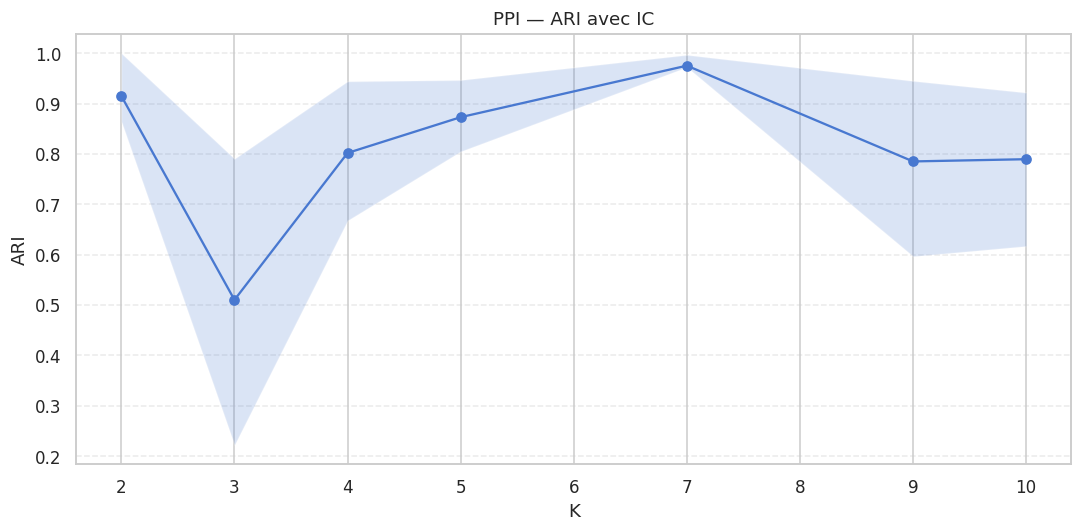

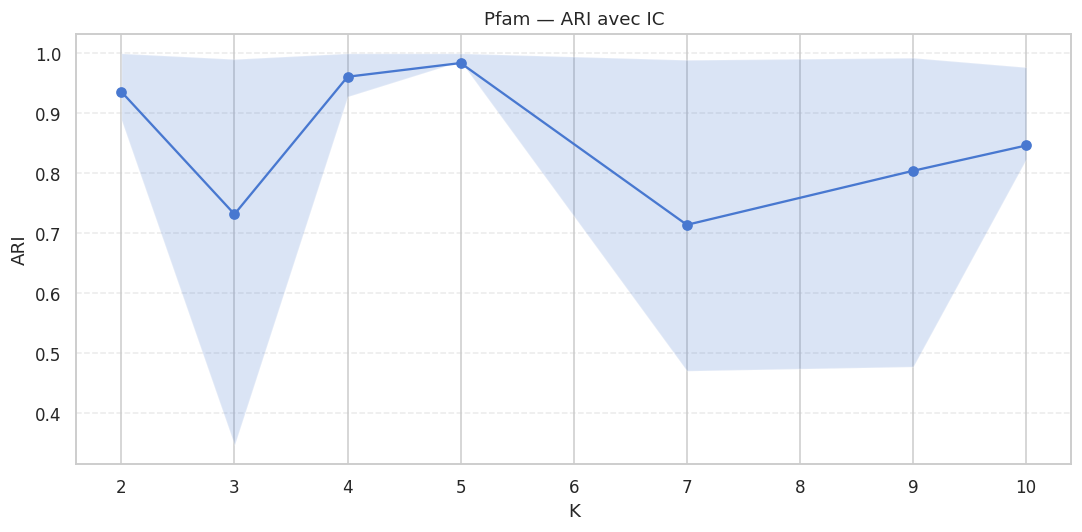

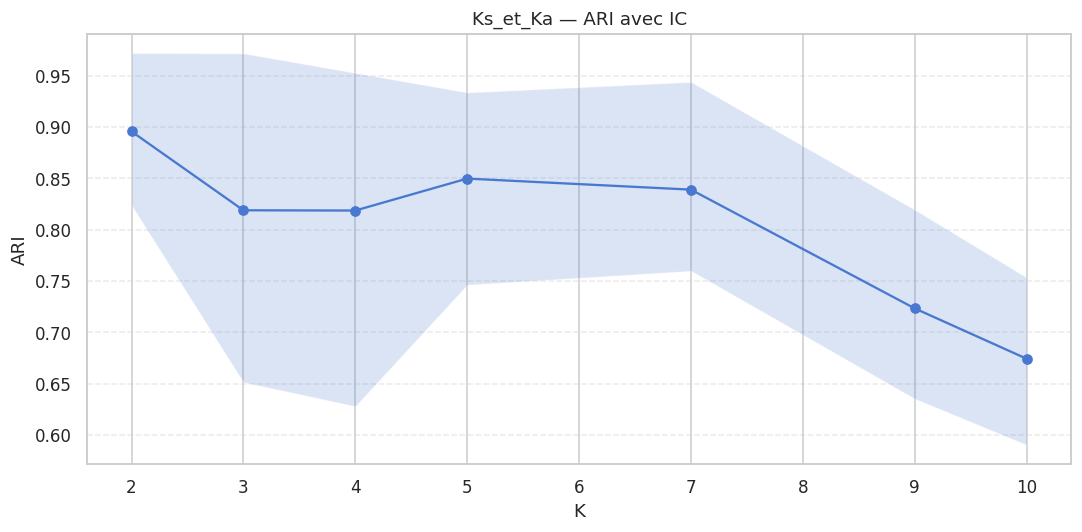

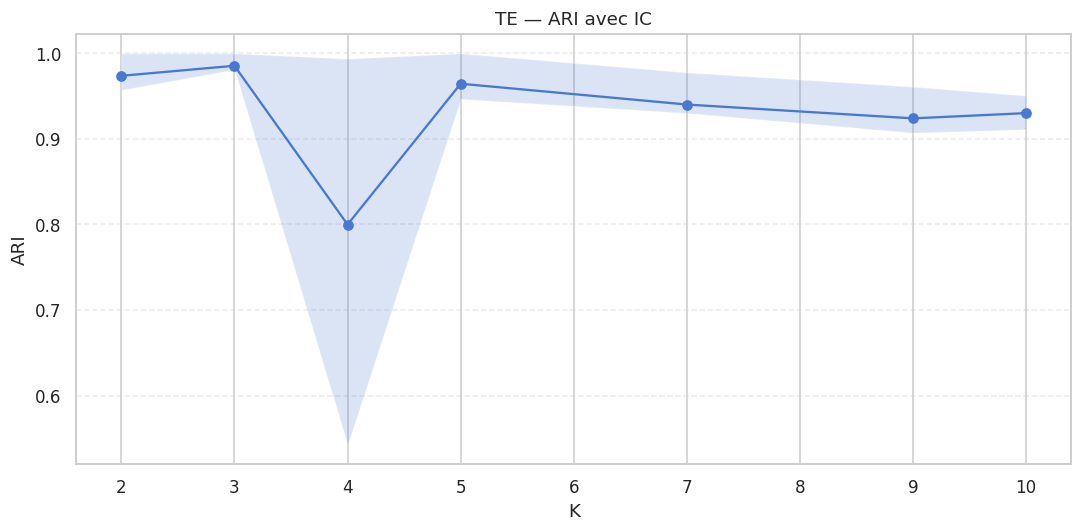

In [14]:
# Visualisation des scores de stabilité 

for family_name in descriptor_families.keys():
    ari_means = [stability_results[family_name][K]["ari_mean"] for K in k_values]
    ari_q25   = [stability_results[family_name][K]["ari_q25"] for K in k_values]
    ari_q75   = [stability_results[family_name][K]["ari_q75"] for K in k_values]

    stability_by_ari_df = pd.DataFrame({
        "K": k_values,
        "mean": ari_means,
        "q25": ari_q25,
        "q75": ari_q75
    })

    figsize=(10,5)
    plt.figure(figsize=figsize)
    plt.plot(stability_by_ari_df["K"], stability_by_ari_df["mean"], marker="o")
    plt.fill_between(stability_by_ari_df["K"], stability_by_ari_df["q25"], stability_by_ari_df["q75"], alpha=0.2)
    plt.xlabel("K")
    plt.ylabel("ARI")
    plt.title(f"{family_name} — ARI avec IC")
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.savefig(f"Plots/kmeans/stabilité_{family_name}.png", dpi = 300)
    plt.show()

### Comparaison synthétique des critères

In [15]:

def interpret_k_row(row, best_silhouette, best_ari_mean):
    if row["Partition non triviale ?"] != "Oui":
        return "Partition triviale / cluster dominant"
    if row["Silhouette"] >= best_silhouette * 0.95 and row["ARI moyen"] >= best_ari_mean * 0.90:
        return "Très bon compromis : silhouette et stabilité élevés"
    if row["Silhouette"] >= best_silhouette * 0.90:
        if row["ARI moyen"] >= best_ari_mean * 0.80:
            return "Bon compromis, stabilité correcte"
        return "Bonne cohésion, stabilité moyenne"
    if row["ARI moyen"] >= best_ari_mean * 0.90:
        return "Stabilité forte mais silhouette un peu plus faible"
    return "Moins recommandé : ni cohésion ni stabilité optimales"

def build_final_selection_table(family_name):
    rows = []
    df_partition = summary_tables[family_name].set_index("K")

    for i, K in enumerate(k_values):
        inertia = kmeans_results_original[family_name]["inertia"][i]
        silhouette = kmeans_results_original[family_name]["silhouette"][i]
        ari_mean = stability_results[family_name][K]["ari_mean"]
        ari_median = stability_results[family_name][K]["ari_median"]
        taille_min = df_partition.loc[K, "Taille min"]
        taille_max = df_partition.loc[K, "Taille max"]
        partition_ok = df_partition.loc[K, "Acceptabilité partition"]
        partition_ok = "Oui" if partition_ok == "Oui" else "Non"

        rows.append({
            "K": K,
            "Inertie": inertia,
            "Silhouette": silhouette,
            "ARI moyen": ari_mean,
            "ARI médian": ari_median,
            "Taille min": taille_min,
            "Taille max": taille_max,
            "Partition non triviale ?": partition_ok,
        })

    table = pd.DataFrame(rows)
    best_silhouette = table["Silhouette"].max()
    best_ari_mean = table["ARI moyen"].max()
    table["Interprétation"] = table.apply(
        lambda row: interpret_k_row(row, best_silhouette, best_ari_mean), axis=1
    )
    return table

ppi_to_summarize = "PPI"  # ou "Pfam", "Ks_et_Ka", "TE"
final_table_ppi = build_final_selection_table(ppi_to_summarize)

print("Table PPI : \n")
final_table_ppi

Table PPI : 



,K,Inertie,Silhouette,ARI moyen,ARI médian,Taille min,Taille max,Partition non triviale ?,Interprétation
0,2,1310.107572,0.792636,0.915224,0.942058,19,425,Non,Partition triviale / cluster dominant
1,3,976.218979,0.773499,0.510336,0.457851,8,422,Non,Partition triviale / cluster dominant
2,4,644.234955,0.558140,0.802123,0.839347,5,310,Oui,Moins recommandé : ni cohésion ni stabilité op...
3,5,418.708958,0.605527,0.873206,0.873906,2,333,Oui,Moins recommandé : ni cohésion ni stabilité op...
4,7,251.067191,0.555605,0.975540,0.988495,2,263,Oui,Stabilité forte mais silhouette un peu plus fa...
5,9,191.285365,0.550160,0.785313,0.850586,2,263,Oui,Moins recommandé : ni cohésion ni stabilité op...
6,10,167.040467,0.506534,0.789736,0.860331,2,189,Oui,Moins recommandé : ni cohésion ni stabilité op...


In [16]:
pfam_to_summarize = "Pfam"
final_table_pfam = build_final_selection_table(pfam_to_summarize)

print(f"Table Pfam : \n")
final_table_pfam

Table Pfam : 



,K,Inertie,Silhouette,ARI moyen,ARI médian,Taille min,Taille max,Partition non triviale ?,Interprétation
0,2,1361.557634,0.805292,0.935999,0.962117,18,426,Non,Partition triviale / cluster dominant
1,3,962.615329,0.602152,0.731954,0.867896,13,345,Oui,Moins recommandé : ni cohésion ni stabilité op...
2,4,621.541870,0.651385,0.961002,0.960925,9,324,Oui,Stabilité forte mais silhouette un peu plus fa...
3,5,456.716207,0.639999,0.983852,0.997914,8,310,Oui,Stabilité forte mais silhouette un peu plus fa...
4,7,305.210302,0.540105,0.714258,0.738154,8,166,Oui,Moins recommandé : ni cohésion ni stabilité op...
5,9,231.447388,0.565569,0.804265,0.922112,4,271,Oui,Moins recommandé : ni cohésion ni stabilité op...
6,10,205.185148,0.552121,0.846435,0.868282,3,158,Oui,Moins recommandé : ni cohésion ni stabilité op...


In [17]:
kska_to_summarize = "Ks_et_Ka"
final_table_kska = build_final_selection_table(kska_to_summarize)


print(f"Table Ks Ka : \n")
final_table_kska

Table Ks Ka : 



,K,Inertie,Silhouette,ARI moyen,ARI médian,Taille min,Taille max,Partition non triviale ?,Interprétation
0,2,2185.222109,0.363249,0.895636,0.916005,147,297,Oui,Très bon compromis : silhouette et stabilité é...
1,3,1686.751422,0.362578,0.818812,0.890026,1,297,Oui,Très bon compromis : silhouette et stabilité é...
2,4,1353.985958,0.375619,0.818555,0.905376,1,244,Oui,Très bon compromis : silhouette et stabilité é...
3,5,1109.393251,0.318774,0.849706,0.877342,1,201,Oui,Stabilité forte mais silhouette un peu plus fa...
4,7,829.821504,0.329920,0.838930,0.841233,1,179,Oui,Stabilité forte mais silhouette un peu plus fa...
5,9,678.843189,0.282302,0.723187,0.714889,1,113,Oui,Moins recommandé : ni cohésion ni stabilité op...
6,10,628.902413,0.294671,0.674116,0.659475,1,113,Oui,Moins recommandé : ni cohésion ni stabilité op...


In [18]:
te_to_summarize = "TE"
final_table_te = build_final_selection_table(te_to_summarize)

print(f"Table TE : \n")
final_table_te

Table TE : 



,K,Inertie,Silhouette,ARI moyen,ARI médian,Taille min,Taille max,Partition non triviale ?,Interprétation
0,2,1377.700978,0.574495,0.973747,0.985760,155,289,Oui,Très bon compromis : silhouette et stabilité é...
1,3,920.655331,0.585507,0.985496,0.995117,22,275,Oui,Très bon compromis : silhouette et stabilité é...
2,4,762.100987,0.530384,0.799949,0.966508,22,142,Oui,"Bon compromis, stabilité correcte"
3,5,613.572812,0.547648,0.964497,0.988902,14,140,Oui,"Bon compromis, stabilité correcte"
4,7,438.165948,0.524782,0.940181,0.958952,6,140,Oui,Stabilité forte mais silhouette un peu plus fa...
5,9,356.816471,0.552763,0.924020,0.936467,5,139,Oui,"Bon compromis, stabilité correcte"
6,10,320.567831,0.537988,0.930148,0.929601,2,139,Oui,"Bon compromis, stabilité correcte"


### Évaluation et visualisation des clusters K-means sans t-SNE

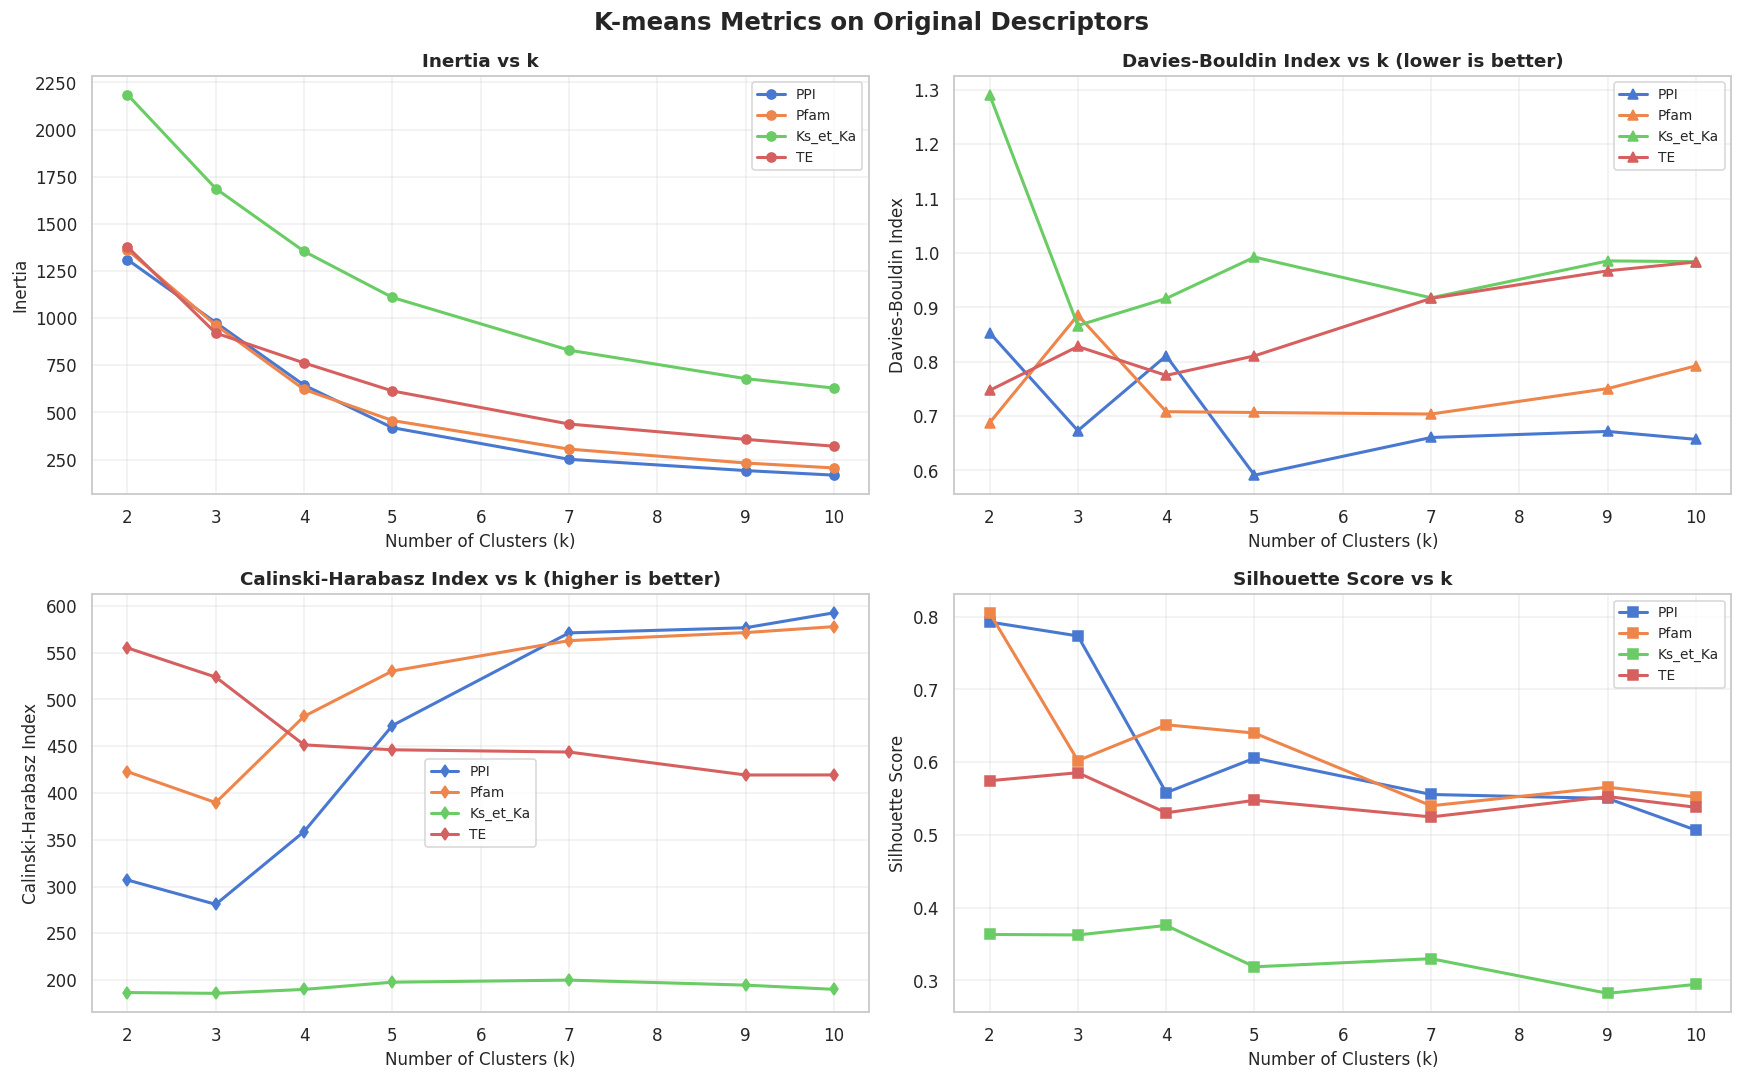


Résumé des métriques pour k=2:
--------------------------------------------------------------------------------
  Family Inertia Silhouette Davies-Bouldin Calinski-Harabasz
     PPI 1310.11     0.7926         0.8535            306.98
    Pfam 1361.56     0.8053         0.6876            422.81
Ks_et_Ka 2185.22     0.3632         1.2914            186.65
      TE 1377.70     0.5745         0.7473            555.12


In [19]:
# Visualiser les métriques pour chaque famille
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('K-means Metrics on Original Descriptors', fontsize=16, fontweight='bold')

# Inertia
ax = axes[0, 0]
for family_name in kmeans_results_original.keys():
    ax.plot(k_values, kmeans_results_original[family_name]['inertia'], 
            marker='o', label=family_name, linewidth=2)
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Inertia', fontsize=11)
ax.set_title('Inertia vs k', fontsize=12, fontweight='bold')
ax.legend(fontsize=9, loc='best')
ax.grid(True, alpha=0.3)

# Davies-Bouldin Index (lower is better)
ax = axes[0, 1]
for family_name in kmeans_results_original.keys():
    ax.plot(k_values, kmeans_results_original[family_name]['davies_bouldin'], 
            marker='^', label=family_name, linewidth=2)
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Davies-Bouldin Index', fontsize=11)
ax.set_title('Davies-Bouldin Index vs k (lower is better)', fontsize=12, fontweight='bold')
ax.legend(fontsize=9, loc='best')
ax.grid(True, alpha=0.3)

# Calinski-Harabasz Index (higher is better)
ax = axes[1, 0]
for family_name in kmeans_results_original.keys():
    ax.plot(k_values, kmeans_results_original[family_name]['calinski_harabasz'], 
            marker='d', label=family_name, linewidth=2)
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Calinski-Harabasz Index', fontsize=11)
ax.set_title('Calinski-Harabasz Index vs k (higher is better)', fontsize=12, fontweight='bold')
ax.legend(fontsize=9, loc='best')
ax.grid(True, alpha=0.3)

# Silhouette Score
ax = axes[1, 1]
for family_name in kmeans_results_original.keys():
    ax.plot(k_values, kmeans_results_original[family_name]['silhouette'], 
            marker='s', label=family_name, linewidth=2)
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Silhouette Score', fontsize=11)
ax.set_title('Silhouette Score vs k', fontsize=12, fontweight='bold')
ax.legend(fontsize=9, loc='best')
ax.grid(True, alpha=0.3)


plt.tight_layout()
plt.savefig('Plots/kmeans/family/original_metrics_comparison.png', dpi=300)
plt.show()

print("\nRésumé des métriques pour k=2:")
print("-" * 80)
summary_data = []
for family_name in kmeans_results_original.keys():
    summary_data.append({
        'Family': family_name,
        'Inertia': f"{kmeans_results_original[family_name]['inertia'][0]:.2f}",
        'Silhouette': f"{kmeans_results_original[family_name]['silhouette'][0]:.4f}",
        'Davies-Bouldin': f"{kmeans_results_original[family_name]['davies_bouldin'][0]:.4f}",
        'Calinski-Harabasz': f"{kmeans_results_original[family_name]['calinski_harabasz'][0]:.2f}"
    })
summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

### K-means pour descripteurs pour famille Ks_Ka

In [20]:
# fais moi un K-means pour les descripteurs de la famille Ks_et_Ka avec k = 2
family_name = 'Ks_et_Ka'
X_family_kska = X_scaled[descriptor_families[family_name]]
X_family_kska.shape

(444, 7)

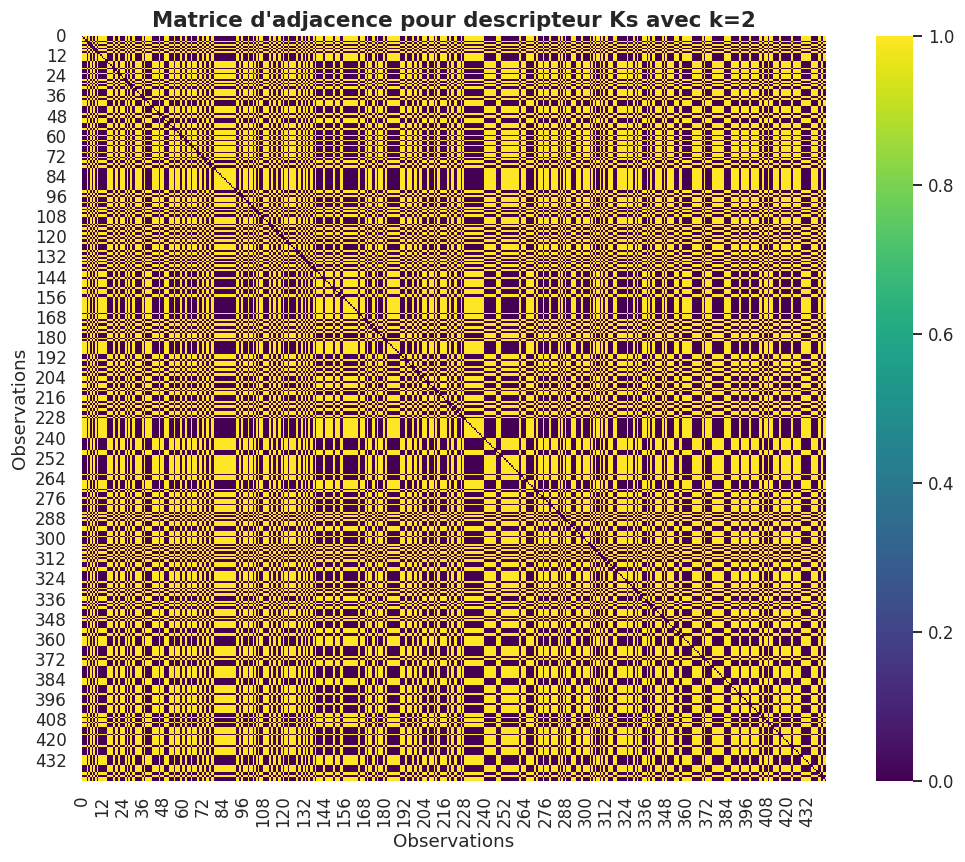

Matrice d'adjacence pour 'Ks' shape: (444, 444), paires: 49546


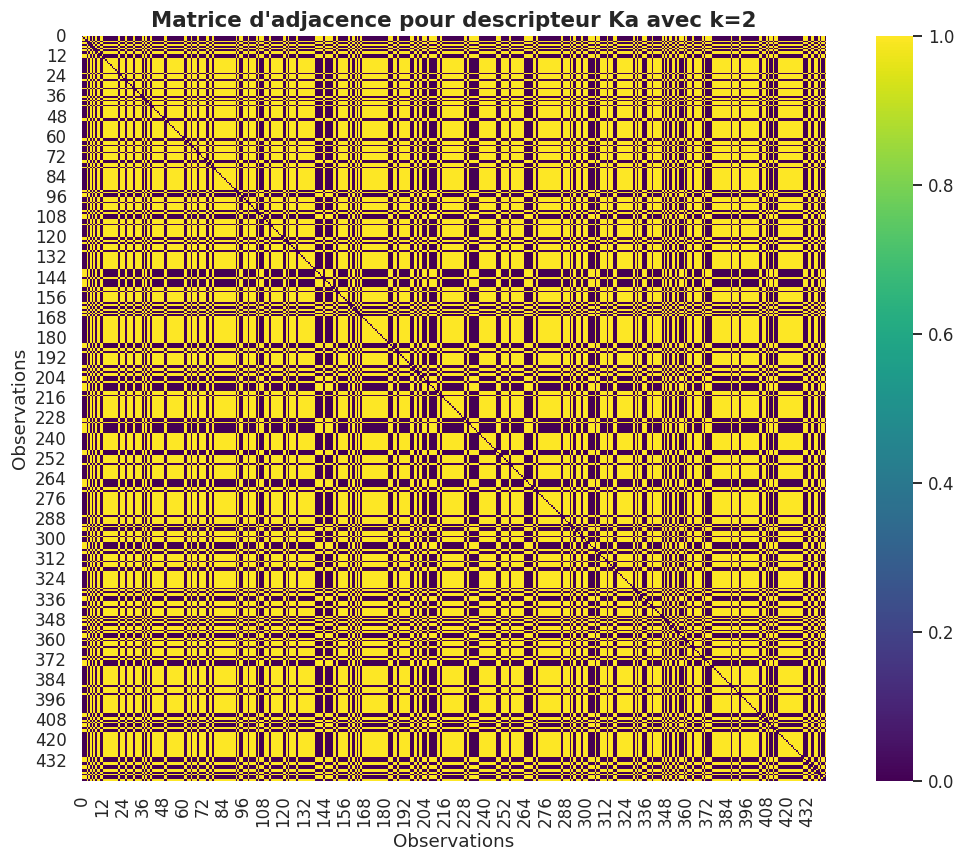

Matrice d'adjacence pour 'Ka' shape: (444, 444), paires: 56118


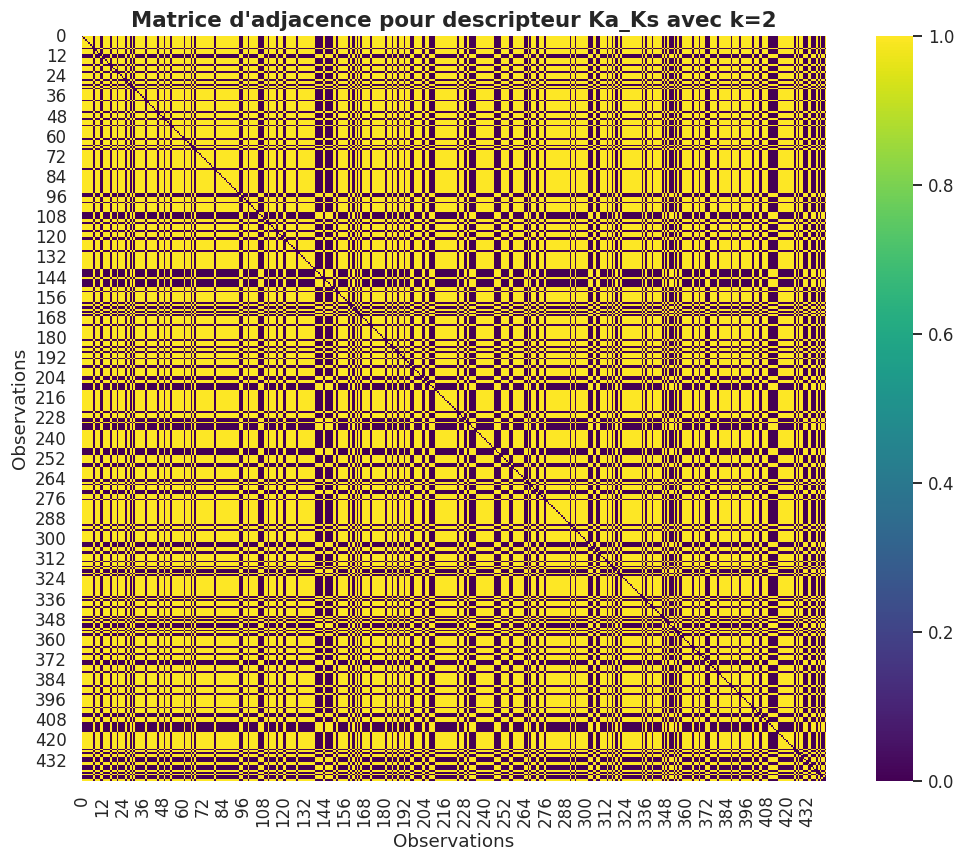

Matrice d'adjacence pour 'Ka_Ks' shape: (444, 444), paires: 58087


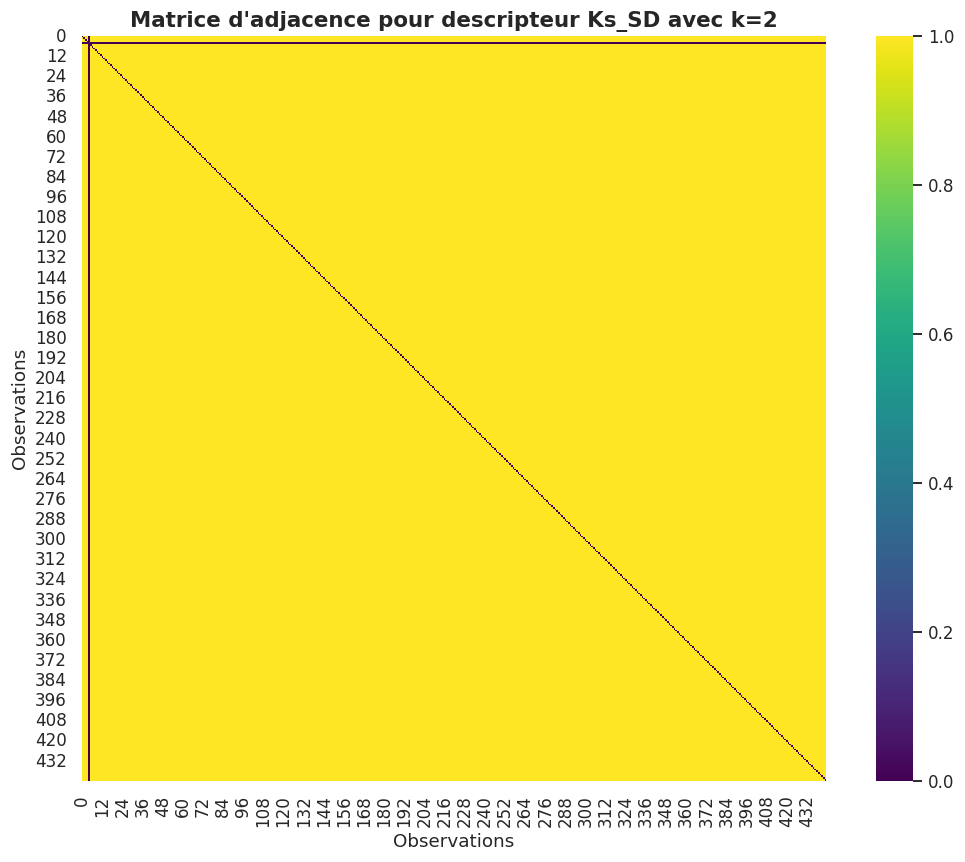

Matrice d'adjacence pour 'Ks_SD' shape: (444, 444), paires: 97903


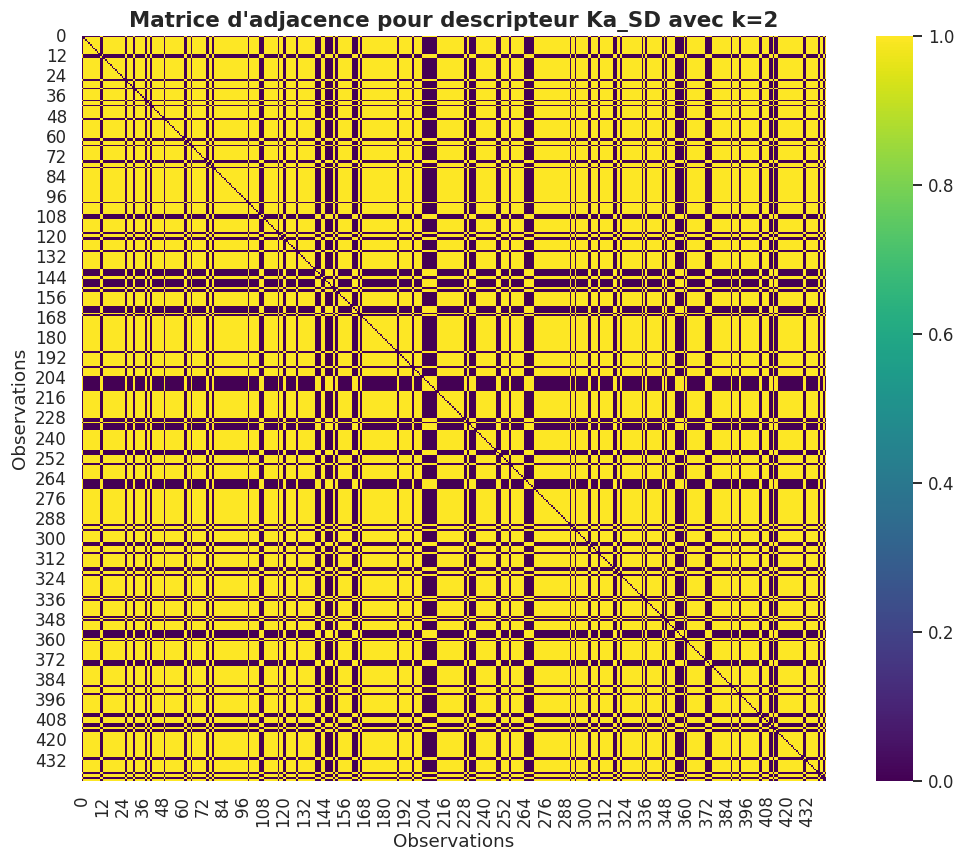

Matrice d'adjacence pour 'Ka_SD' shape: (444, 444), paires: 64191


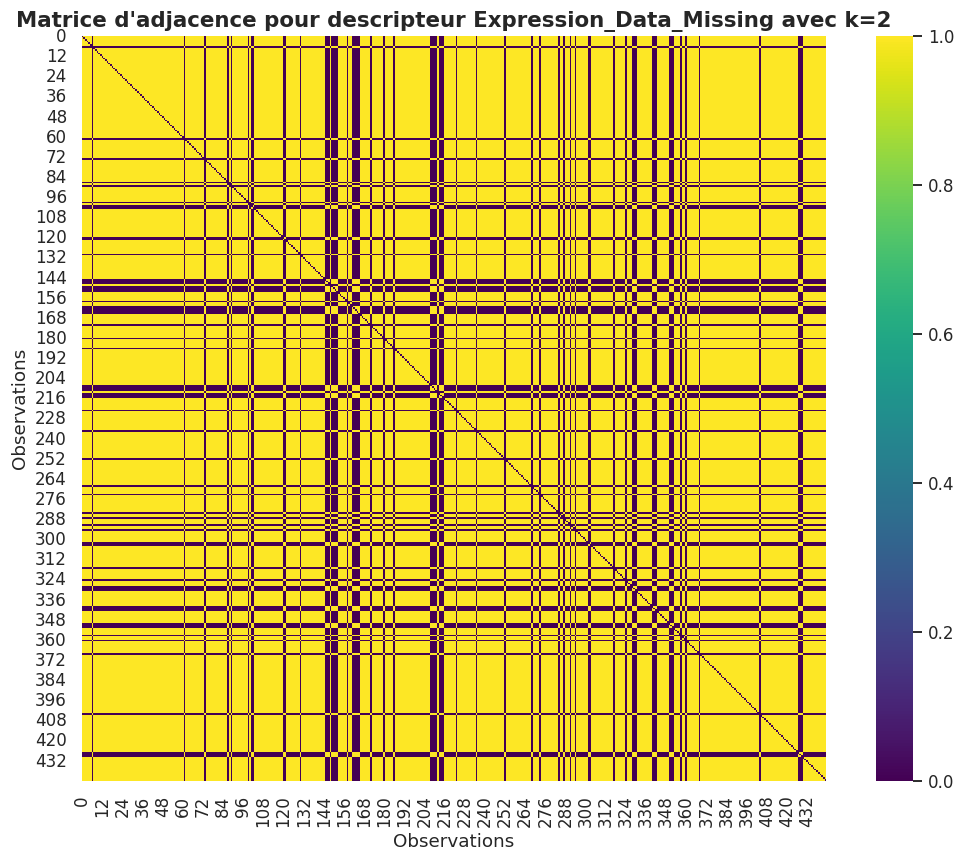

Matrice d'adjacence pour 'Expression_Data_Missing' shape: (444, 444), paires: 74343


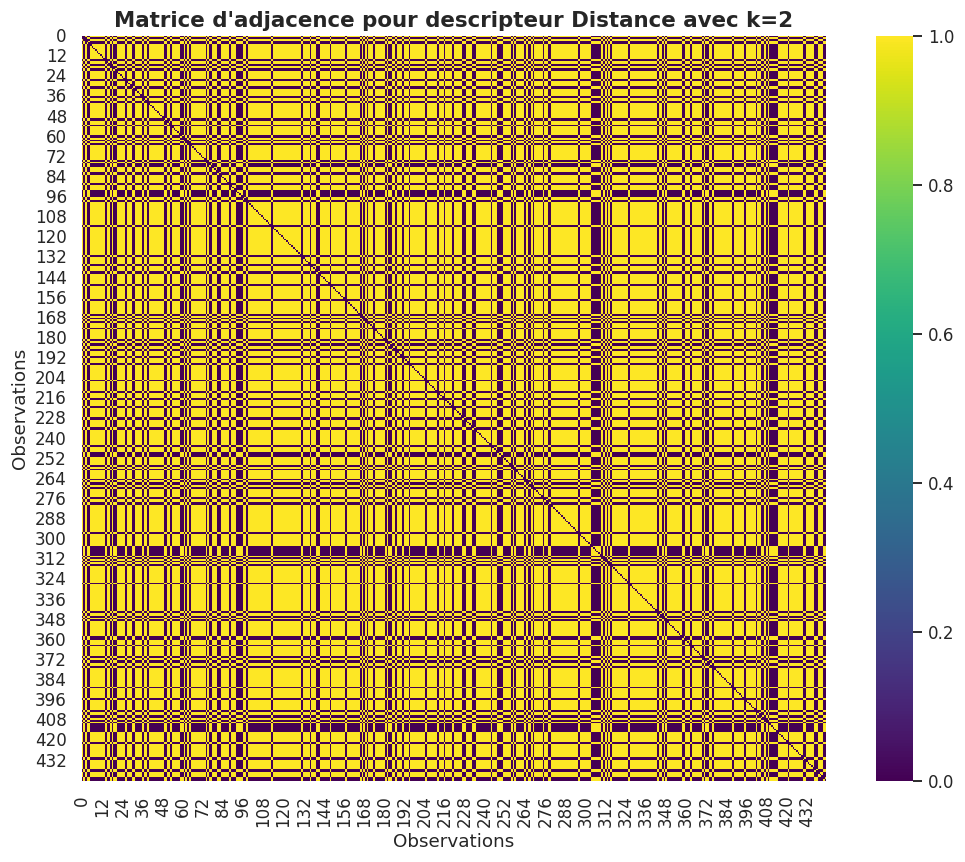

Matrice d'adjacence pour 'Distance' shape: (444, 444), paires: 62287


In [21]:
# Générer une matrice d'adjacence par descripteur pour la famille Ks_et_Ka
family_name = 'Ks_et_Ka'
kska_cols = descriptor_families[family_name]
adjacency_matrices_kska = {}

for col in kska_cols:
    X_col = X_scaled[[col]]
    k = 2
    kmeans_col = KMeans(n_clusters=k, n_init=n_init, random_state=random_state, init='k-means++')
    labels_col = kmeans_col.fit_predict(X_col)

    Z_col = pd.DataFrame({
        'Cluster': labels_col,
        col: X_col[col]
    })

    Z_col_binary = pd.get_dummies(Z_col['Cluster'], prefix='Cluster').astype(int)
    adjacency_matrix_col = Z_col_binary.values @ Z_col_binary.values.T
    adjacency_matrix_col = adjacency_matrix_col - np.diag(np.diag(adjacency_matrix_col))

    adjacency_matrices_kska[col] = adjacency_matrix_col
    
    # Heatmap de la matrice d'adjacence pour les descripteurs de la famille Ks_et_Ka
    plt.figure(figsize=(10, 8))
    sns.heatmap(adjacency_matrix_col, cmap='viridis', cbar=True, square=True)
    plt.title(f'Matrice d\'adjacence pour descripteur {col} avec k={k}', fontsize=14, fontweight='bold')
    plt.xlabel('Observations', fontsize=12)
    plt.ylabel('Observations', fontsize=12)
    plt.tight_layout()
    # plt.savefig(f'Plots/kmeans/adjacency_matrix_{family_name}_k{k}.png', dpi=300)
    plt.show()
    print(f"Matrice d'adjacence pour '{col}' shape: {adjacency_matrix_col.shape}, paires: {(adjacency_matrix_col.sum()/2):.0f}")


In [22]:
# Exporter matruces d'adjacence pour la famille Ks_et_Ka
for col, adjacency_matrix in adjacency_matrices_kska.items():
    np.savetxt(f'Données/adjacency/Ks_et_Ka/adjacency_matrix_{col}.csv', adjacency_matrix, delimiter=',', fmt='%d')

In [23]:
# Additionner les matrices d'adjacence des descripteurs de la famille KsKa et compter le nombre de 2, 3, 4 dans la matrice résultante
total_adjacency_kska_sum = np.zeros_like(list(adjacency_matrices_kska.values())[0])
for adjacency_matrix in adjacency_matrices_kska.values():
    total_adjacency_kska_sum += adjacency_matrix

num_zeros_kska = (np.sum(total_adjacency_kska_sum == 0)  - 444 )/ 2 # Nombre de paires de points dans le même cluster pour exactement 1 famille
num_ones_kska = np.sum(total_adjacency_kska_sum == 1) / 2 # Nombre de paires de points dans le même cluster pour exactement 1 famille
num_twos_kska = np.sum(total_adjacency_kska_sum == 2) / 2 # Nombre de paires de points dans le même cluster pour exactement 2 familles
num_threes_kska = np.sum(total_adjacency_kska_sum == 3) / 2 # Nombre de paires de points dans le même cluster pour exactement 3 familles
num_fours_kska = np.sum(total_adjacency_kska_sum == 4) / 2 # Nombre de paires de points dans le même cluster pour exactement 4 familles
num_fives_kska = np.sum(total_adjacency_kska_sum == 5) / 2 # Nombre de paires de points dans le même cluster pour exactement 5 familles
num_six_kska = np.sum(total_adjacency_kska_sum == 6) / 2 # Nombre de paires de points dans le même cluster pour exactement 6 familles
num_sevens_kska = np.sum(total_adjacency_kska_sum == 7) / 2 # Nombre de paires de points dans le même cluster pour exactement 7 familles

print(f"Nb paires dans même cluster pour 0 descripteur: {num_zeros_kska:.0f}")
print(f"Nb paires dans même cluster pour 1 descripteur: {num_ones_kska:.0f}")
print(f"Nb paires dans même cluster pour 2 descripteurs: {num_twos_kska:.0f}")
print(f"Nb paires dans même cluster pour 3 descripteurs: {num_threes_kska:.0f}")
print(f"Nb paires dans même cluster pour 4 descripteurs: {num_fours_kska:.0f}")
print(f"Nb paires dans même cluster pour 5 descripteurs: {num_fives_kska:.0f}")
print(f"Nb paires dans même cluster pour 6 descripteurs: {num_six_kska:.0f}")
print(f"Nb paires dans même cluster pour 7 descripteurs: {num_sevens_kska:.0f}")
print(f"Vérification: Total paires = {num_zeros_kska + num_ones_kska + num_twos_kska + num_threes_kska + num_fours_kska + num_fives_kska + num_six_kska + num_sevens_kska:.0f} (devrait être 98346)")

Nb paires dans même cluster pour 0 descripteur: 0
Nb paires dans même cluster pour 1 descripteur: 1096
Nb paires dans même cluster pour 2 descripteurs: 9082
Nb paires dans même cluster pour 3 descripteurs: 15407
Nb paires dans même cluster pour 4 descripteurs: 16105
Nb paires dans même cluster pour 5 descripteurs: 20273
Nb paires dans même cluster pour 6 descripteurs: 23472
Nb paires dans même cluster pour 7 descripteurs: 12911
Vérification: Total paires = 98346 (devrait être 98346)


### K-means pour descripteurs pour famille TE

In [24]:
family_name = 'TE'
X_family_te = X_scaled[descriptor_families[family_name]]
X_family_te.shape

(444, 7)

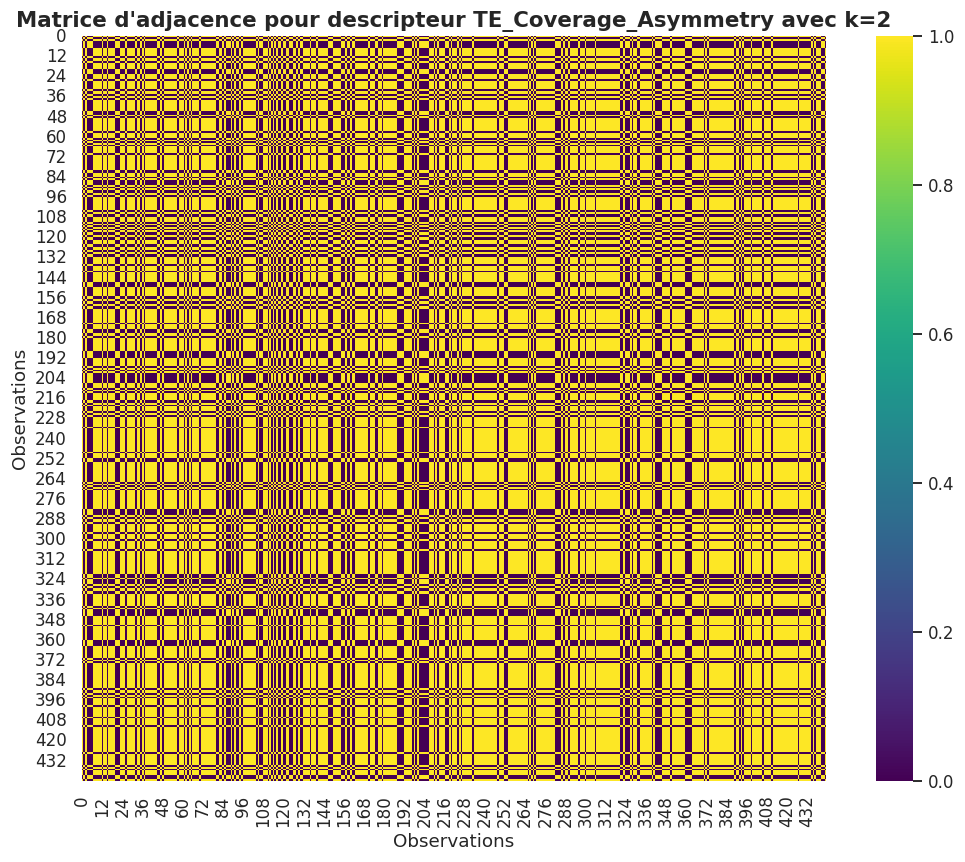

Matrice d'adjacence pour 'TE_Coverage_Asymmetry' shape: (444, 444), paires: 58120


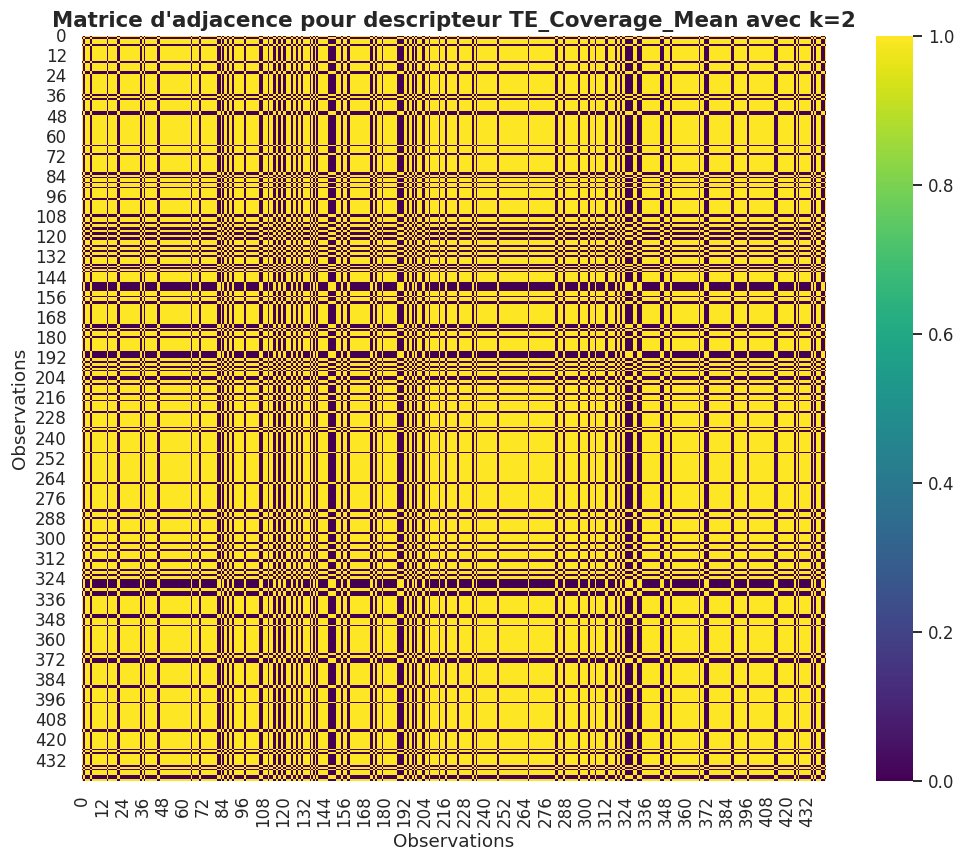

Matrice d'adjacence pour 'TE_Coverage_Mean' shape: (444, 444), paires: 64909


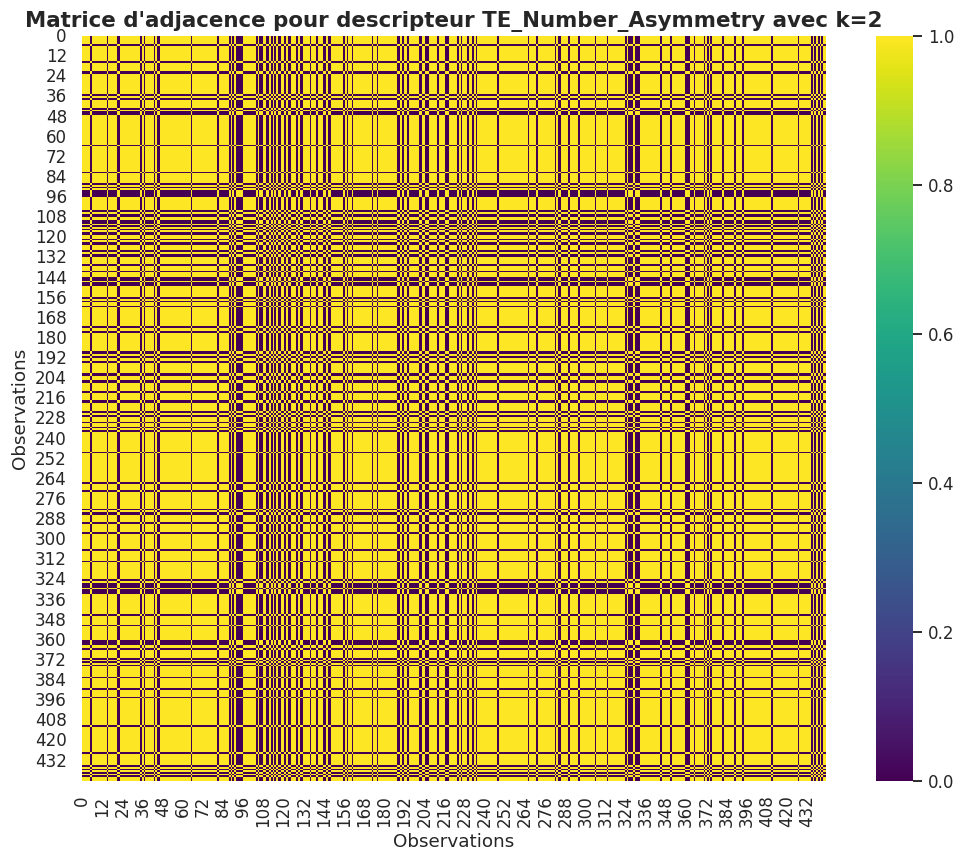

Matrice d'adjacence pour 'TE_Number_Asymmetry' shape: (444, 444), paires: 65668


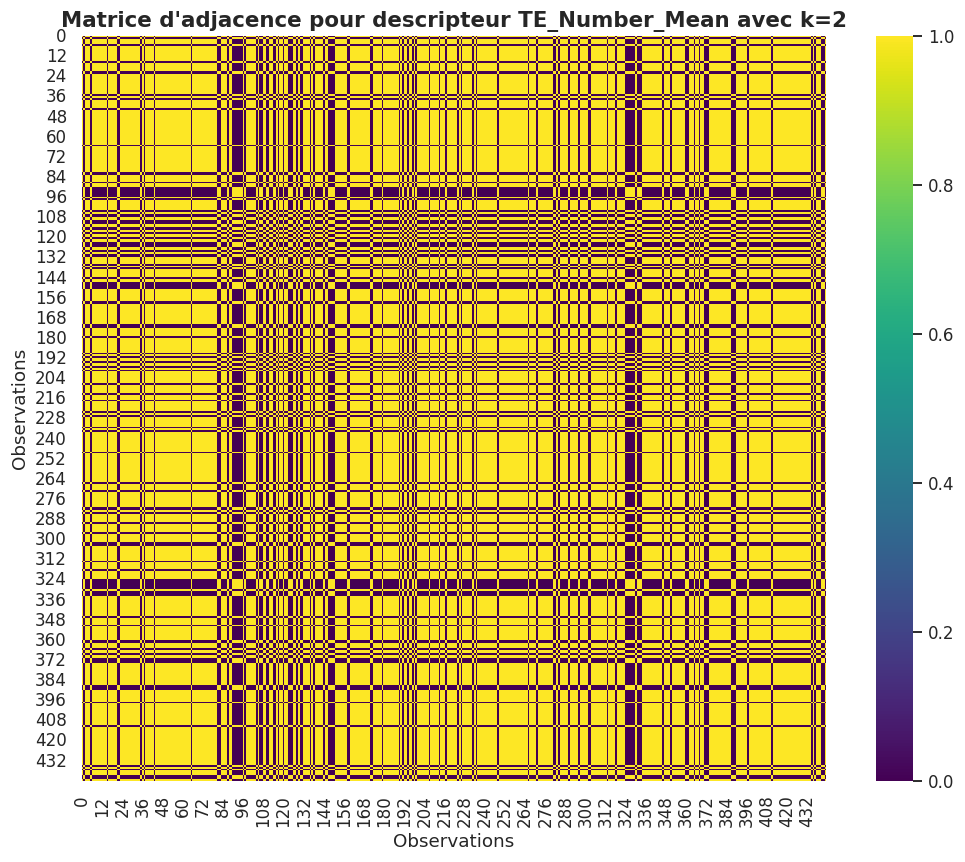

Matrice d'adjacence pour 'TE_Number_Mean' shape: (444, 444), paires: 64909


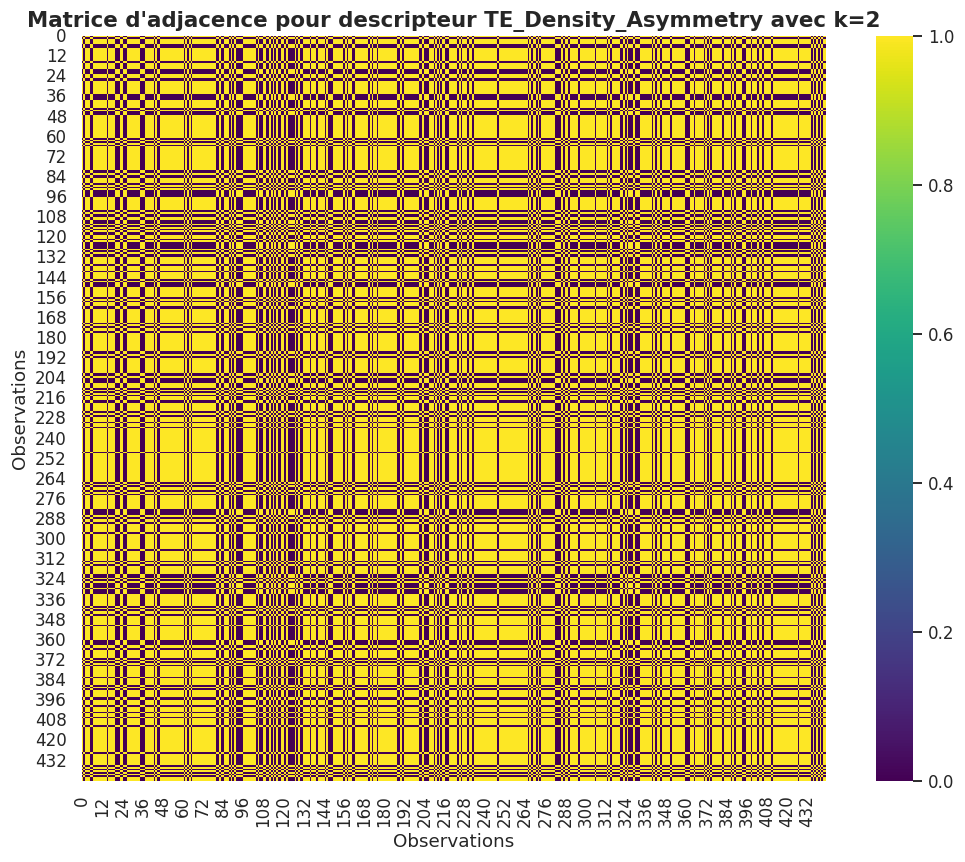

Matrice d'adjacence pour 'TE_Density_Asymmetry' shape: (444, 444), paires: 58888


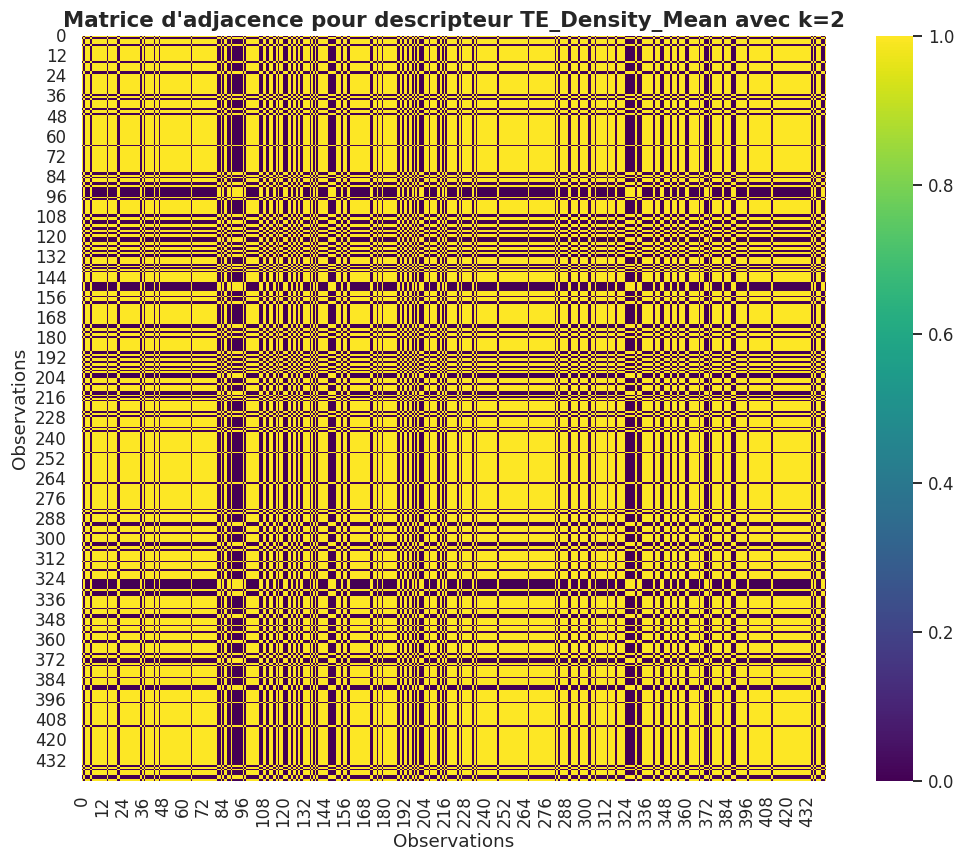

Matrice d'adjacence pour 'TE_Density_Mean' shape: (444, 444), paires: 61384


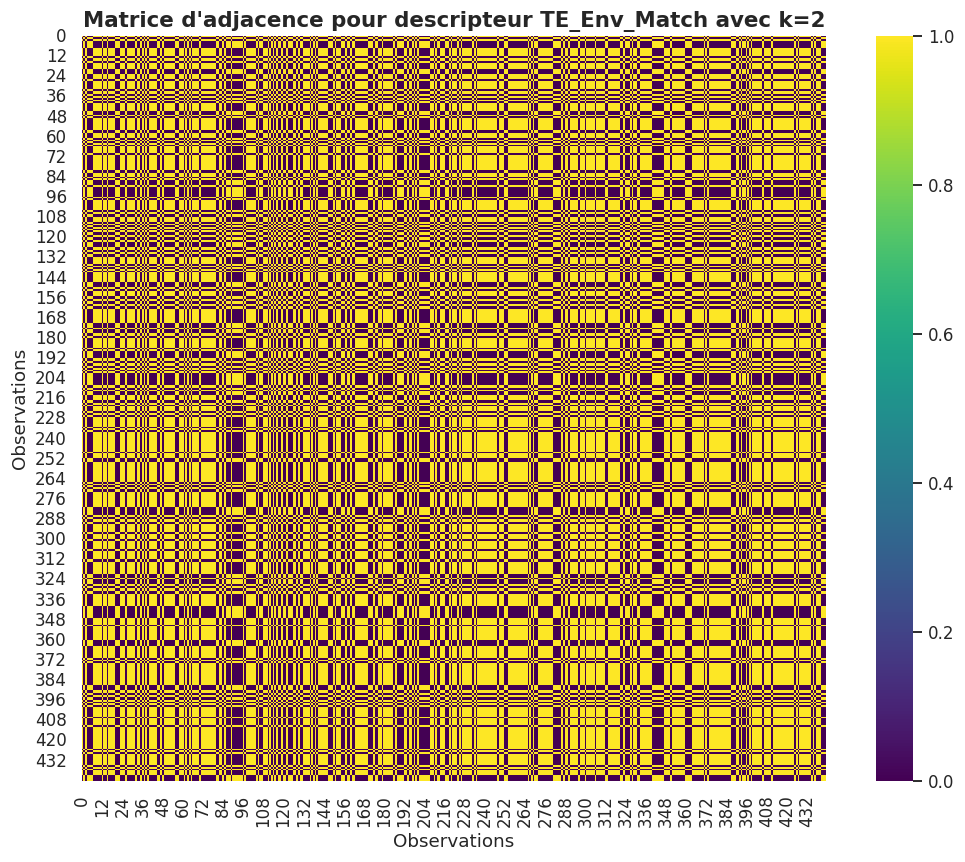

Matrice d'adjacence pour 'TE_Env_Match' shape: (444, 444), paires: 53773


In [25]:
# Générer une matrice d'adjacence par descripteur pour la famille TE
family_name = 'TE'
te_cols = descriptor_families[family_name]
adjacency_matrices_te = {}

for col in te_cols:
    X_col = X_scaled[[col]]
    k = 2
    kmeans_col = KMeans(n_clusters=k, n_init=n_init, random_state=random_state, init='k-means++')
    labels_col = kmeans_col.fit_predict(X_col)

    Z_col = pd.DataFrame({
        'Cluster': labels_col,
        col: X_col[col]
    })

    Z_col_binary = pd.get_dummies(Z_col['Cluster'], prefix='Cluster').astype(int)
    adjacency_matrix_col_te = Z_col_binary.values @ Z_col_binary.values.T
    adjacency_matrix_col = adjacency_matrix_col_te - np.diag(np.diag(adjacency_matrix_col_te))

    adjacency_matrices_te[col] = adjacency_matrix_col_te
    
    # Heatmap de la matrice d'adjacence pour les descripteurs de la famille TE
    plt.figure(figsize=(10, 8))
    sns.heatmap(adjacency_matrix_col_te, cmap='viridis', cbar=True, square=True)
    plt.title(f'Matrice d\'adjacence pour descripteur {col} avec k={k}', fontsize=14, fontweight='bold')
    plt.xlabel('Observations', fontsize=12)
    plt.ylabel('Observations', fontsize=12)
    plt.tight_layout()
    # plt.savefig(f'Plots/kmeans/adjacency_matrix_{family_name}_k{k}.png', dpi=300)
    plt.show()
    print(f"Matrice d'adjacence pour '{col}' shape: {adjacency_matrix_col_te.shape}, paires: {(adjacency_matrix_col_te.sum()/2):.0f}")


In [26]:
# Exporter matruces d'adjacence pour la famille TE
for col, adjacency_matrix in adjacency_matrices_te.items():
    np.savetxt(f'Données/adjacency/TE/adjacency_matrix_{col}.csv', adjacency_matrix, delimiter=',', fmt='%d')

In [27]:
# Additionner les matrices d'adjacence des descripteurs de la famille TE et compter le nombre de 2, 3, 4 dans la matrice résultante
total_adjacency_te_sum = np.zeros_like(list(adjacency_matrices_te.values())[0])
for adjacency_matrix in adjacency_matrices_te.values():
    total_adjacency_te_sum += adjacency_matrix

num_zeros_te = (np.sum(total_adjacency_te_sum == 0)  - 444 )/ 2 # Nombre de paires de points dans le même cluster pour exactement 1 famille
num_ones_te = np.sum(total_adjacency_te_sum == 1) / 2 # Nombre de paires de points dans le même cluster pour exactement 1 famille
num_twos_te = np.sum(total_adjacency_te_sum == 2) / 2 # Nombre de paires de points dans le même cluster pour exactement 2 familles
num_threes_te = np.sum(total_adjacency_te_sum == 3) / 2 # Nombre de paires de points dans le même cluster pour exactement 3 familles
num_fours_te = np.sum(total_adjacency_te_sum == 4) / 2 # Nombre de paires de points dans le même cluster pour exactement 4 familles
num_fives_te = np.sum(total_adjacency_te_sum == 5) / 2 # Nombre de paires de points dans le même cluster pour exactement 5 familles
num_six_te = np.sum(total_adjacency_te_sum == 6) / 2 # Nombre de paires de points dans le même cluster pour exactement 6 familles
num_sevens_te = np.sum(total_adjacency_te_sum == 7) / 2 # Nombre de paires de points dans le même cluster pour exactement 7 familles

print(f"Nb paires dans même cluster pour 0 descripteur: {num_zeros_te:.0f}")
print(f"Nb paires dans même cluster pour 1 descripteur: {num_ones_te:.0f}")
print(f"\nNb paires dans même cluster pour 2 descripteurs: {num_twos_te:.0f}")
print(f"Nb paires dans même cluster pour 3 descripteurs: {num_threes_te:.0f}")
print(f"Nb paires dans même cluster pour 4 descripteurs: {num_fours_te:.0f}")
print(f"Nb paires dans même cluster pour 5 descripteurs: {num_fives_te:.0f}")
print(f"Nb paires dans même cluster pour 6 descripteurs: {num_six_te:.0f}")
print(f"Nb paires dans même cluster pour 7 descripteurs: {num_sevens_te:.0f}")
print(f"Vérification: Total paires = {num_zeros_te + num_ones_te + num_twos_te + num_threes_te + num_fours_te + num_fives_te + num_six_te + num_sevens_te:.0f} (devrait être 98346)")

Nb paires dans même cluster pour 0 descripteur: 10095
Nb paires dans même cluster pour 1 descripteur: 7008

Nb paires dans même cluster pour 2 descripteurs: 8983
Nb paires dans même cluster pour 3 descripteurs: 10533
Nb paires dans même cluster pour 4 descripteurs: 11459
Nb paires dans même cluster pour 5 descripteurs: 9995
Nb paires dans même cluster pour 6 descripteurs: 6644
Nb paires dans même cluster pour 7 descripteurs: 33629
Vérification: Total paires = 98346 (devrait être 98346)


### Matrices Z selon les clusters par famille sans composantes t-SNE

In [28]:
# Récupérer la matrice d'adjacence pour les clusters K-means par famille de descripteurs
family_adjacency_matrices = {}

for family_name, cols in descriptor_families.items():

    if (family_name== 'Pfam'):
        optimal_k_visua_direct = 5
    elif family_name == 'PPI':
        optimal_k_visua_direct = 5
    elif family_name == 'Ks_et_Ka':
        optimal_k_visua_direct = 2
    else:
        optimal_k_visua_direct = 3
    
    X_family = X_scaled[cols]
    kmeans_family = KMeans(n_clusters=optimal_k_visua_direct, n_init=n_init, random_state=random_state, init='k-means++')
    labels_family = kmeans_family.fit_predict(X_family)
    
    Z_family = pd.DataFrame(X_family, columns=X_family.columns)
    Z_family['Cluster'] = labels_family
    
    Z_family_binary = pd.get_dummies(Z_family['Cluster'], prefix='Cluster').astype(int)
    
    adjacency_matrix_family = Z_family_binary.values @ Z_family_binary.values.T
    adjacency_matrix_family = adjacency_matrix_family - np.diag(np.diag(adjacency_matrix_family))  # Soustraire les éléments diagonaux
    family_adjacency_matrices[family_name] = adjacency_matrix_family
    
    print(f"\nMatrice d'adjacence pour la famille '{family_name}':")
    print(f"Shape: {adjacency_matrix_family.shape}")
    print(f"Nombre de paires dans le même cluster: {(adjacency_matrix_family.sum()/2):.0f}")
    # Diviser par 2 pour ne pas compter les paires (i,j) et (j,i)


Matrice d'adjacence pour la famille 'PPI':
Shape: (444, 444)
Nombre de paires dans le même cluster: 58187

Matrice d'adjacence pour la famille 'Pfam':
Shape: (444, 444)
Nombre de paires dans le même cluster: 51338

Matrice d'adjacence pour la famille 'Ks_et_Ka':
Shape: (444, 444)
Nombre de paires dans le même cluster: 54687

Matrice d'adjacence pour la famille 'TE':
Shape: (444, 444)
Nombre de paires dans le même cluster: 48637


In [29]:
# Sauvegarder les matrices d'adjacence dans un fichier CSV
for family_name, adjacency_matrix in family_adjacency_matrices.items():
    adjacency_df = pd.DataFrame(adjacency_matrix, index=X_scaled.index, columns=X_scaled.index)
    adjacency_df.to_csv(f'Données/adjacency_matrix_{family_name}.csv')
    print(f"Matrice d'adjacence pour la famille '{family_name}' sauvegardée dans 'Données/adjacency_matrix_{family_name}.csv'")

Matrice d'adjacence pour la famille 'PPI' sauvegardée dans 'Données/adjacency_matrix_PPI.csv'
Matrice d'adjacence pour la famille 'Pfam' sauvegardée dans 'Données/adjacency_matrix_Pfam.csv'
Matrice d'adjacence pour la famille 'Ks_et_Ka' sauvegardée dans 'Données/adjacency_matrix_Ks_et_Ka.csv'
Matrice d'adjacence pour la famille 'TE' sauvegardée dans 'Données/adjacency_matrix_TE.csv'


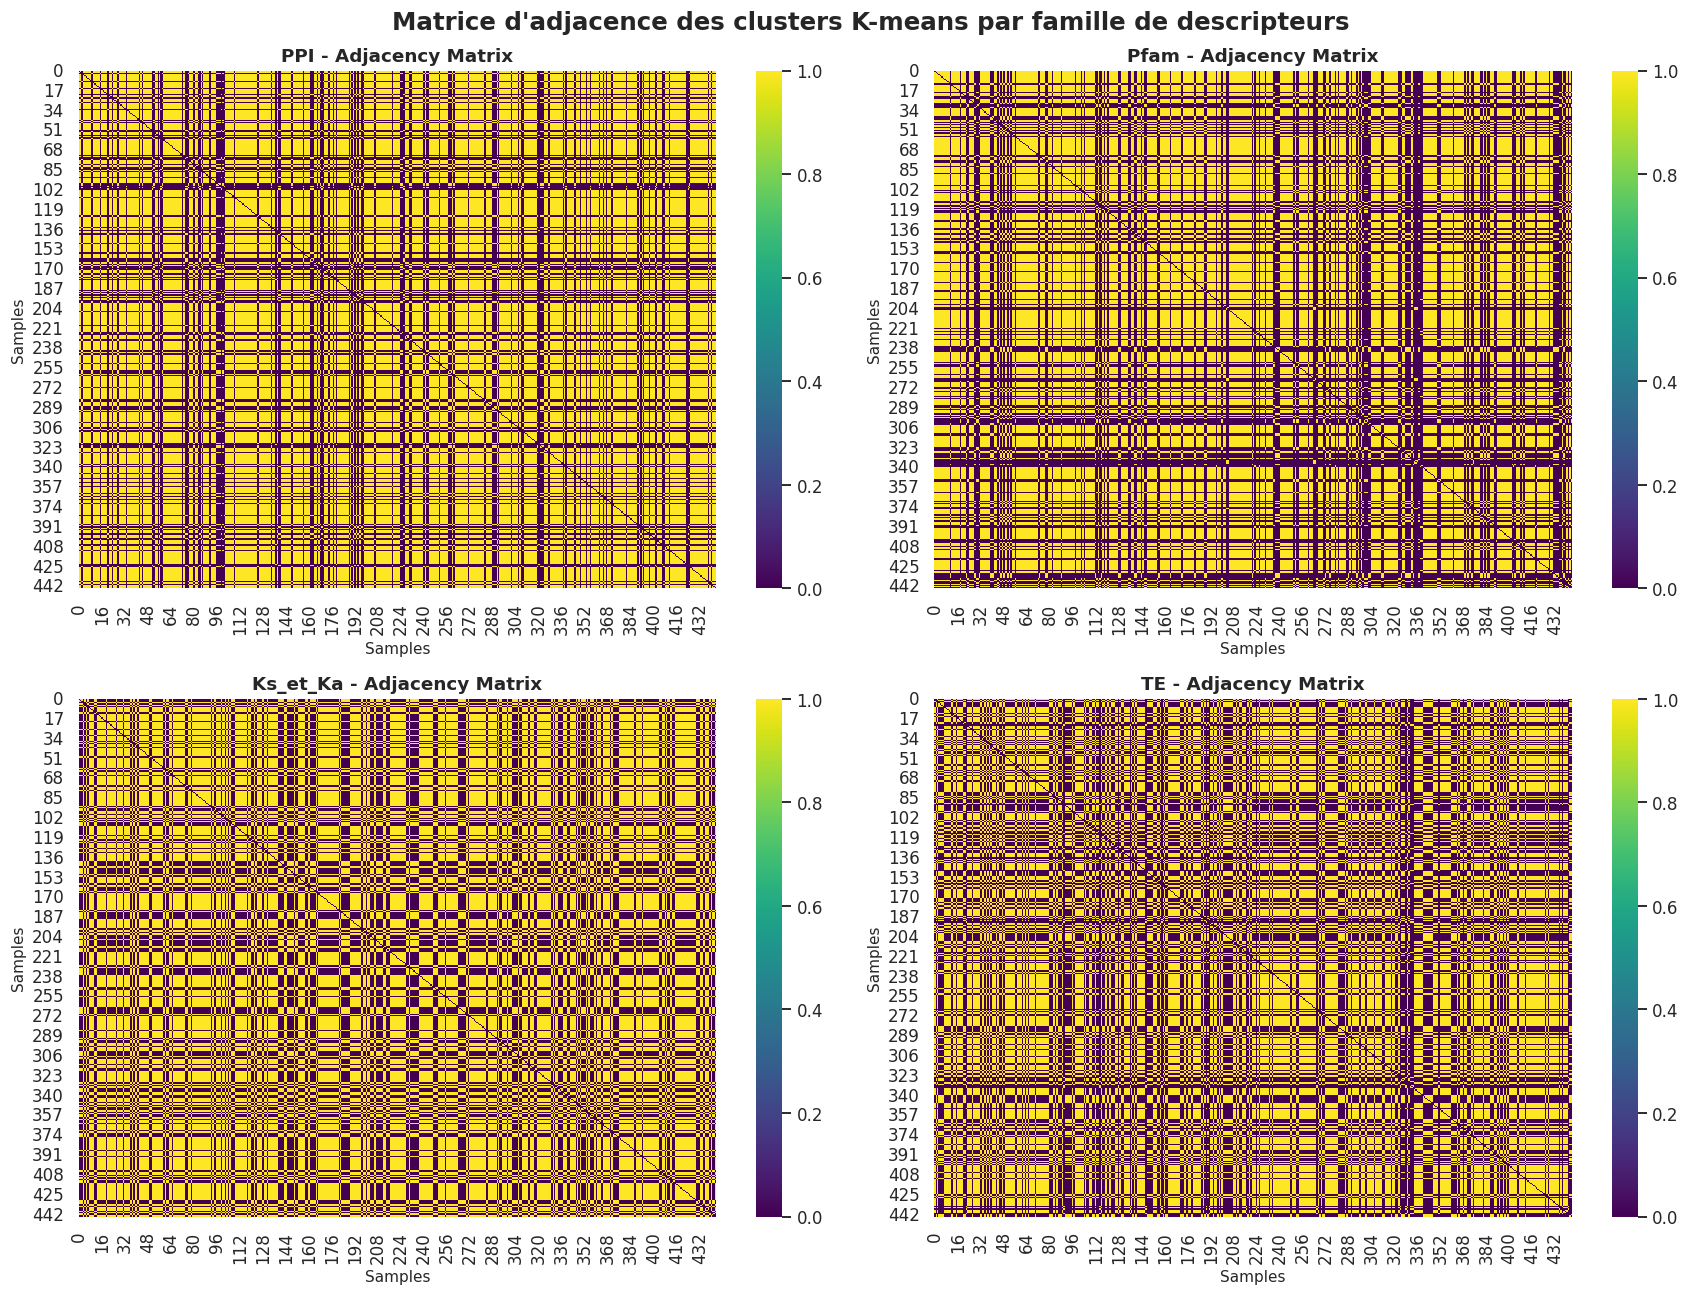

In [30]:
# Heatmap de la matrice d'adjacence par famille de descripteurs
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Matrice d\'adjacence des clusters K-means par famille de descripteurs', fontsize=16, fontweight='bold')
for idx, (family_name, adjacency_matrix) in enumerate(family_adjacency_matrices.items()):
    ax = axes[idx // 2, idx % 2]
    sns.heatmap(adjacency_matrix, ax=ax, cmap='viridis', cbar=True)
    ax.set_title(f'{family_name} - Adjacency Matrix', fontsize=12, fontweight='bold')
    ax.set_xlabel('Samples', fontsize=10)
    ax.set_ylabel('Samples', fontsize=10)
plt.tight_layout()
# plt.savefig('Plots/kmeans/family/adjacency_matrices.png', dpi=300)
plt.show()

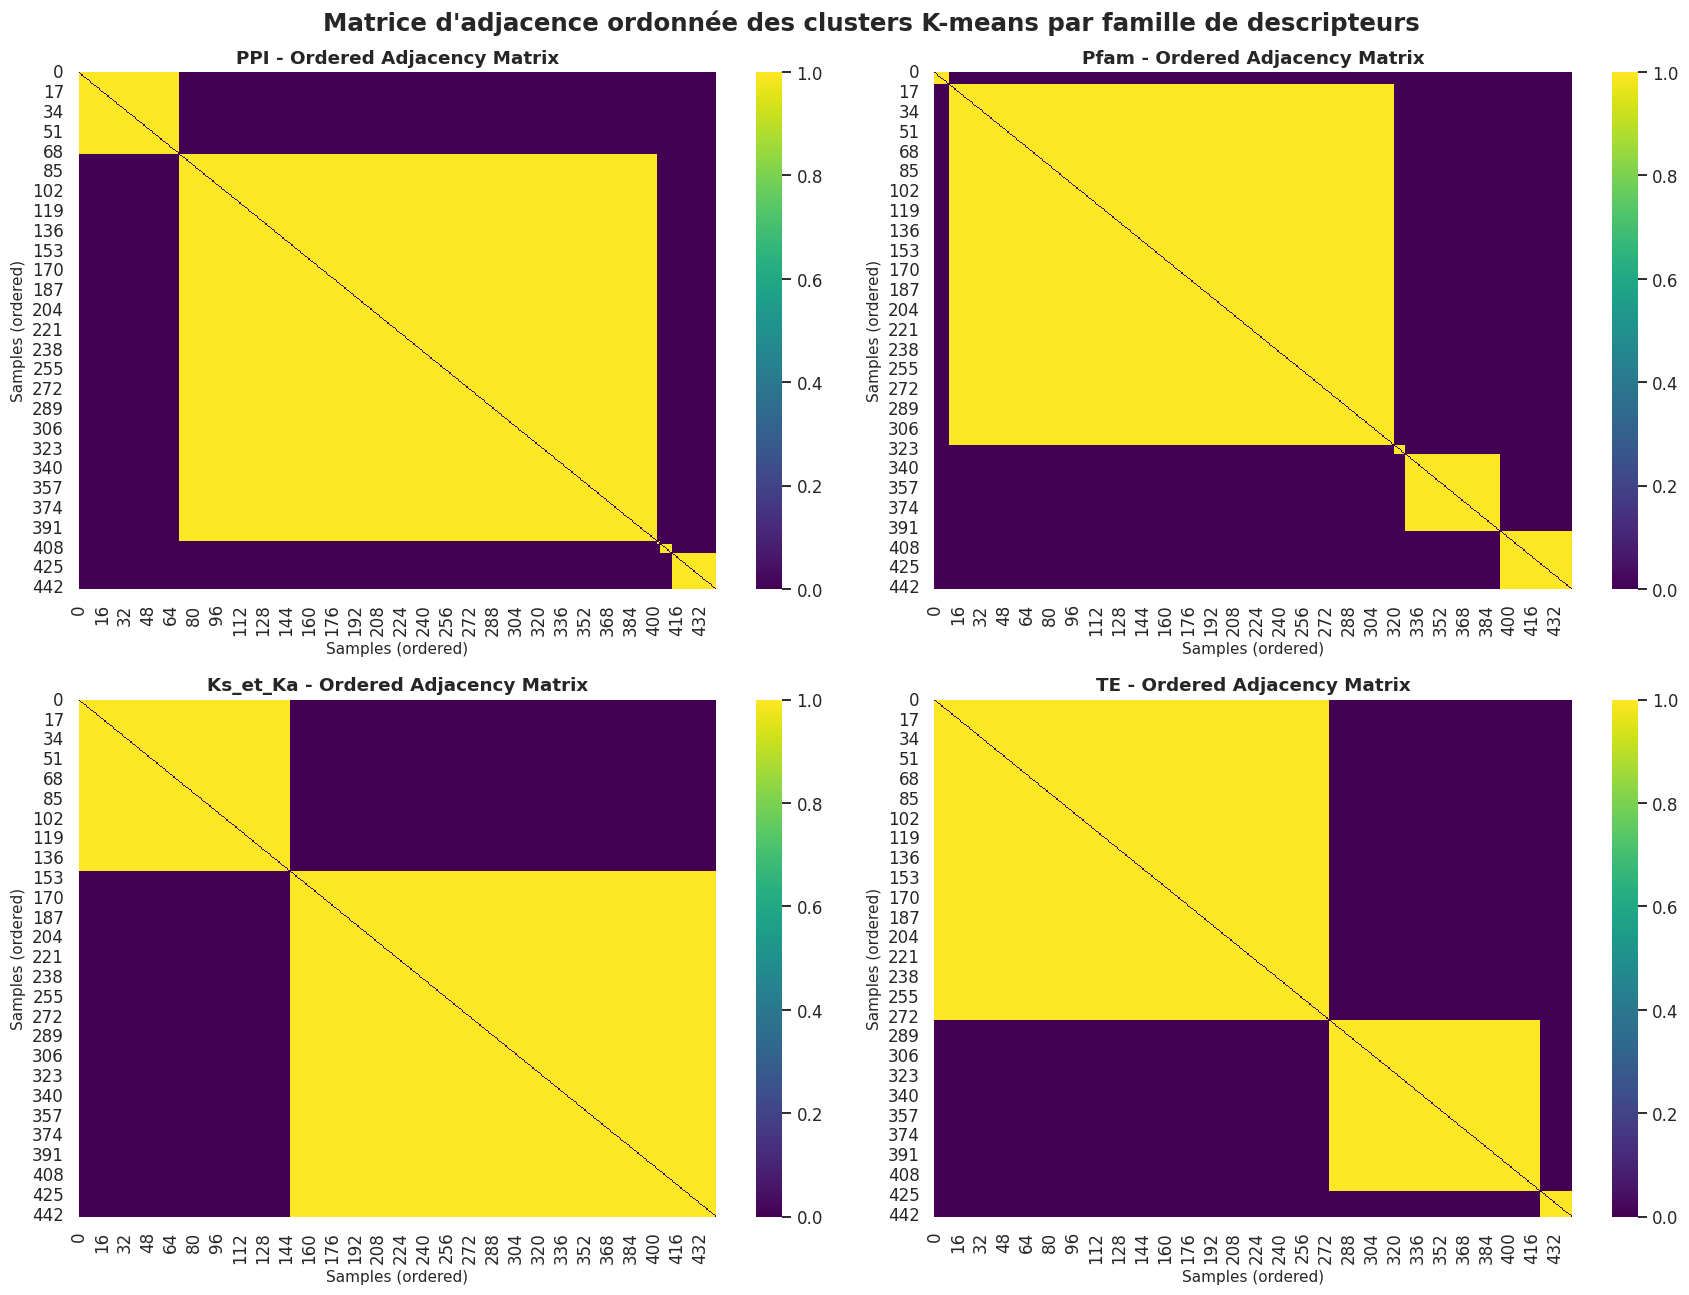

In [31]:
# Ordonnancement matrice d'adjacence pour regrouper les points appartenant au même cluster
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Matrice d\'adjacence ordonnée des clusters K-means par famille de descripteurs', fontsize=16, fontweight='bold')
for idx, (family_name, adjacency_matrix) in enumerate(family_adjacency_matrices.items()):
    ax = axes[idx // 2, idx % 2]
    
    # Recalculer les clusters pour cette famille spécifique
    if (family_name== 'Pfam'):
        optimal_k_visua = 5
    elif family_name == 'PPI':
        optimal_k_visua = 5
    elif family_name == 'Ks_et_Ka':
        optimal_k_visua = 2
    else:
        optimal_k_visua = 3
    X_family = X_scaled[descriptor_families[family_name]]
    kmeans_family = KMeans(n_clusters=optimal_k_visua, n_init=n_init, random_state=random_state, init='k-means++')
    labels_family = kmeans_family.fit_predict(X_family)
    
    # Ordonner la matrice d'adjacence en regroupant les points du même cluster
    ordered_indices = np.argsort(labels_family)
    ordered_adjacency = adjacency_matrix[ordered_indices][:, ordered_indices]
    
    sns.heatmap(ordered_adjacency, ax=ax, cmap='viridis', cbar=True)
    ax.set_title(f'{family_name} - Ordered Adjacency Matrix', fontsize=12, fontweight='bold')
    ax.set_xlabel('Samples (ordered)', fontsize=10)
    ax.set_ylabel('Samples (ordered)', fontsize=10)
plt.tight_layout()
plt.savefig('Plots/kmeans/family/ordered_adjacency_matrices.png', dpi=300)
plt.show()

In [32]:
# Addition des matrices d'adjacence 2 à 2 et on récupére le nombre de 2 dans la matrice résultante pour chaque paire de familles
family_names = list(family_adjacency_matrices.keys())
adjacency_comparison = pd.DataFrame(index=family_names, columns=family_names)
for i in range(len(family_names)):
    for j in range(i, len(family_names)):
        family_i = family_names[i]
        family_j = family_names[j]
        # Addition des matrices d'adjacence
        adjacency_sum = family_adjacency_matrices[family_i] + family_adjacency_matrices[family_j]
        
        # Compter le nombre de 2 dans la matrice résultante
        num_twos = np.sum(adjacency_sum == 2) / 2  # Nombre de paires de points dans le même cluster pour les deux familles

        adjacency_comparison.loc[family_i, family_j] = num_twos
        adjacency_comparison.loc[family_j, family_i] = num_twos  # Symétrique

In [33]:
print("\nComparaison des matrices d'adjacence (nombre de paires de points dans le même cluster):")
print(adjacency_comparison)


Comparaison des matrices d'adjacence (nombre de paires de points dans le même cluster):
              PPI     Pfam Ks_et_Ka       TE
PPI       58187.0  28913.0  31278.0  28301.0
Pfam      28913.0  51338.0  28717.0  25837.0
Ks_et_Ka  31278.0  28717.0  54687.0  27229.0
TE        28301.0  25837.0  27229.0  48637.0


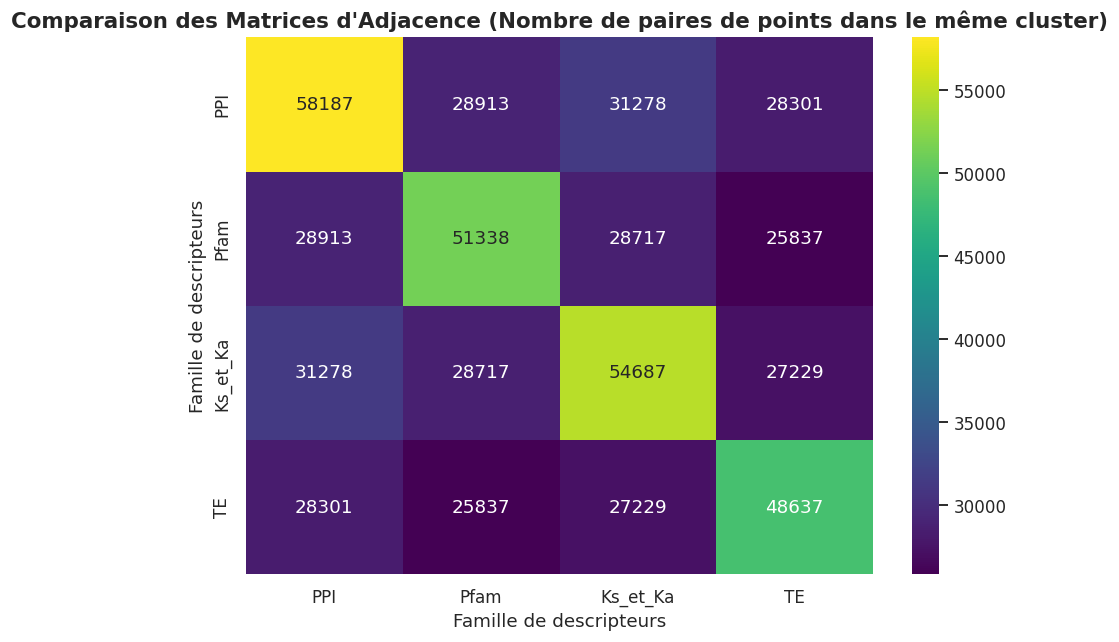

In [34]:
# Faire heatmap de la comparaison des matrices d'adjacence
plt.figure(figsize=(8, 6))
sns.heatmap(adjacency_comparison.astype(float), annot=True, fmt=".0f", cmap='viridis', cbar=True)
plt.title('Comparaison des Matrices d\'Adjacence (Nombre de paires de points dans le même cluster)', fontsize=14, fontweight='bold')
plt.xlabel('Famille de descripteurs', fontsize=12)
plt.ylabel('Famille de descripteurs', fontsize=12)
plt.tight_layout()
# plt.savefig('Plots/kmeans/family/adjacency_comparison_heatmap.png', dpi=300)
plt.show()

In [35]:
# faire ARI sur les clusters K-means par famille de descripteurs
ari_comparison = pd.DataFrame(index=family_names, columns=family_names)
for i in range(len(family_names)):
    for j in range(i, len(family_names)):
        family_i = family_names[i]
        family_j = family_names[j]
        
        labels_i = KMeans(n_clusters=optimal_k_visua, n_init=n_init, random_state=random_state, init='k-means++').fit_predict(X_scaled[descriptor_families[family_i]])
        labels_j = KMeans(n_clusters=optimal_k_visua, n_init=n_init, random_state=random_state, init='k-means++').fit_predict(X_scaled[descriptor_families[family_j]])
        
        ari_score = adjusted_rand_score(labels_i, labels_j)
        
        ari_comparison.loc[family_i, family_j] = ari_score
        ari_comparison.loc[family_j, family_i] = ari_score  # Symétrique

print("\nComparaison des clusters K-means par famille de descripteurs (ARI):")
print(ari_comparison)


Comparaison des clusters K-means par famille de descripteurs (ARI):
               PPI      Pfam  Ks_et_Ka        TE
PPI            1.0 -0.014131  -0.01455 -0.011983
Pfam     -0.014131       1.0  0.022738 -0.011384
Ks_et_Ka  -0.01455  0.022738       1.0  0.008318
TE       -0.011983 -0.011384  0.008318       1.0


In [29]:
# Additionner les valeurs de adjacency_comparison sauf la diagonale pour chaque famille
adjacency_comparison['Total_Same_Cluster_Pairs'] = adjacency_comparison.apply(lambda row: sum(row) - row[row.name], axis=1)
print("\nNombre total de paires de points dans le même cluster pour chaque famille (somme des lignes sans la diagonale):")
print(adjacency_comparison[['Total_Same_Cluster_Pairs']])


Nombre total de paires de points dans le même cluster pour chaque famille (somme des lignes sans la diagonale):
          Total_Same_Cluster_Pairs
PPI                        88492.0
Pfam                       83467.0
Ks_et_Ka                   87224.0
TE                         81367.0


In [30]:
# On va calculer pour chaque famille de descripteurs le nombre de points qui sont dans le même cluster
cluster_comparison = pd.DataFrame(index=family_names, columns=[f'Cluster {i}' for i in range(optimal_k_visua)])
for family_name in family_names:
    # Recalculer les clusters pour cette famille spécifique
    if (family_name== 'Pfam'):
        optimal_k_visua = 5
    elif family_name == 'PPI':
        optimal_k_visua = 5
    elif family_name == 'Ks_et_Ka':
        optimal_k_visua = 2
    else:
        optimal_k_visua = 3
    
    X_family = X_scaled[descriptor_families[family_name]]
    kmeans_family = KMeans(n_clusters=optimal_k_visua, n_init=n_init, random_state=random_state, init='k-means++')
    labels_family = kmeans_family.fit_predict(X_family)
    
    # Compter le nombre de points dans chaque cluster pour cette famille
    for cluster_id in range(optimal_k_visua):
        num_points_in_cluster = np.sum(labels_family == cluster_id)
        cluster_comparison.loc[family_name, f'Cluster {cluster_id}'] = num_points_in_cluster
print("\nComparaison entre les familles de descripteurs et les clusters:")
print(cluster_comparison)


Comparaison entre les familles de descripteurs et les clusters:
         Cluster 0 Cluster 1 Cluster 2  Cluster 3  Cluster 4
PPI             70       333         2        8.0       31.0
Pfam            10       310         8       66.0       50.0
Ks_et_Ka       147       297       NaN        NaN        NaN
TE             275       147        22        NaN        NaN


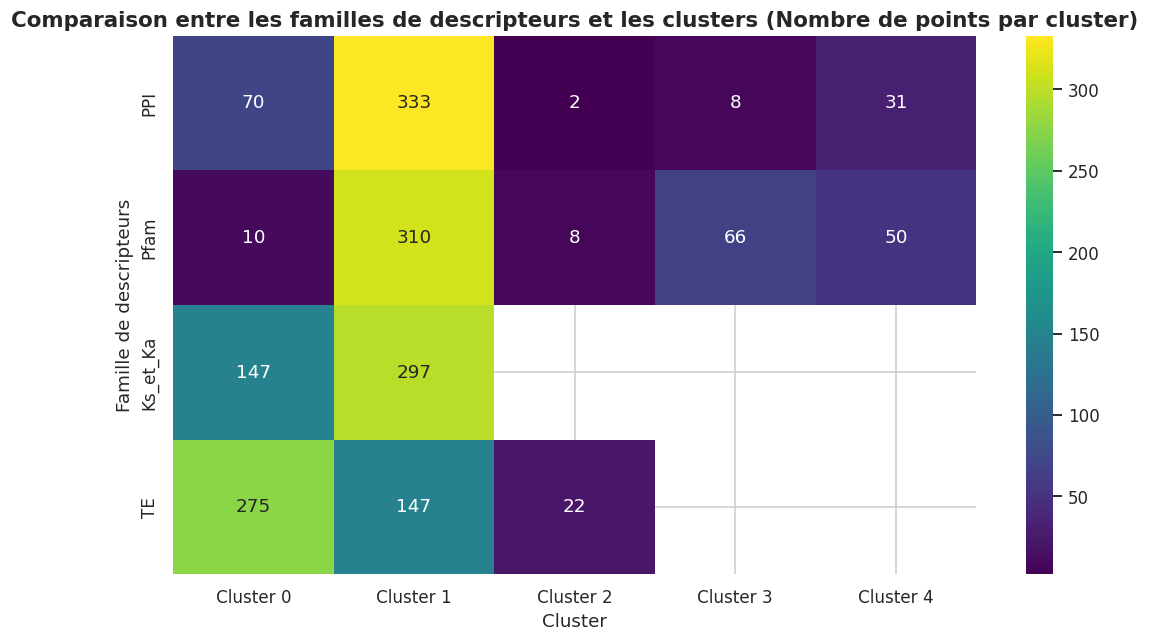

In [31]:
# Faire heatmap de cluster_comparison
plt.figure(figsize=(10, 6))
sns.heatmap(cluster_comparison.astype(float), annot=True, fmt=".0f", cmap='viridis', cbar=True)
plt.title('Comparaison entre les familles de descripteurs et les clusters (Nombre de points par cluster)', fontsize=14, fontweight='bold')
plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Famille de descripteurs', fontsize=12)
plt.tight_layout()
# plt.savefig('Plots/kmeans/family/cluster_comparison_heatmap.png', dpi=300)
plt.show()

In [32]:
# --- Calcul des tailles ET ratios redondant/divergent par cluster ---
max_k = max(7, 5, 2, 3)
columns = [f'Cluster {i}' for i in range(max_k)]

cluster_comparison = pd.DataFrame(index=family_names, columns=columns, dtype=float)
ratio_comparison   = pd.DataFrame(index=family_names, columns=columns, dtype=float)

y_train = pd.read_csv("Données/Y_train_clean.csv")
classifications = y_train['Classification'].values  # 0=redondant, 1=divergent

for family_name in family_names:
    if family_name == 'Pfam':
        optimal_k_visua = 5
    elif family_name == 'PPI':
        optimal_k_visua = 5
    elif family_name == 'Ks_et_Ka':
        optimal_k_visua = 2
    else:
        optimal_k_visua = 3

    X_family = X_scaled[descriptor_families[family_name]]
    kmeans_family = KMeans(n_clusters=optimal_k_visua, n_init=n_init,
                           random_state=random_state, init='k-means++')
    labels_family = kmeans_family.fit_predict(X_family)

    # Calculer taille et ratio pour chaque cluster
    cluster_sizes  = []
    cluster_ratios = []
    for cluster_id in range(optimal_k_visua):
        mask_cluster = labels_family == cluster_id
        n = int(np.sum(mask_cluster))
        n_div = int(np.sum(classifications[mask_cluster] == 1))
        n_red = n - n_div
        ratio = n_red / n_div if n_div > 0 else np.inf  # redondant/divergent
        cluster_sizes.append(n)
        cluster_ratios.append(ratio)

    # Trier les deux listes ensemble par taille décroissante
    sorted_pairs = sorted(zip(cluster_sizes, cluster_ratios), key=lambda x: x[0], reverse=True)

    for rank, (size, ratio) in enumerate(sorted_pairs):
        cluster_comparison.loc[family_name, f'Cluster {rank}'] = size
        ratio_comparison.loc[family_name,   f'Cluster {rank}'] = ratio

# --- Construction des annotations combinées ---
# Chaque cellule affiche : "N pts\nR:D = x.xx"
annot_matrix = pd.DataFrame(index=family_names, columns=columns, dtype=object)
nan_mask = cluster_comparison.isna()

for fam in family_names:
    for col in columns:
        if nan_mask.loc[fam, col]:
            annot_matrix.loc[fam, col] = ""
        else:
            n     = int(cluster_comparison.loc[fam, col])
            ratio = ratio_comparison.loc[fam, col]
            ratio_str = f"{ratio:.2f}" if not np.isinf(ratio) else "∞"
            annot_matrix.loc[fam, col] = f"{n} paires\nR/D={ratio_str}"

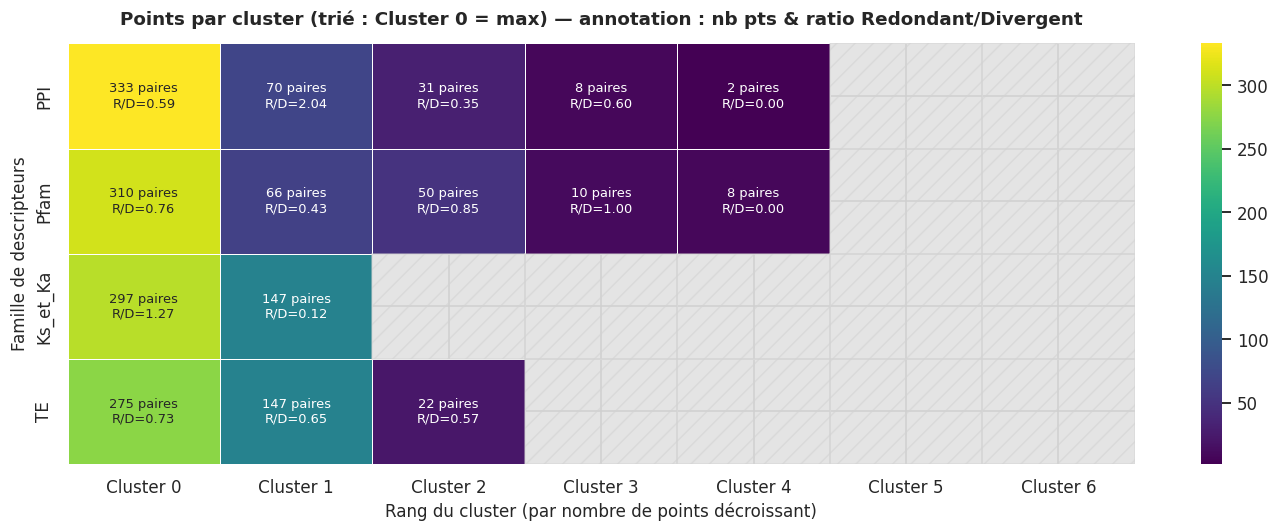

In [33]:
# --- Heatmap ---
fig, ax = plt.subplots(figsize=(13, 5))

sns.heatmap(
    cluster_comparison.astype(float),
    annot=annot_matrix,
    fmt="",                  # fmt vide car les annotations sont des strings
    cmap='viridis',
    cbar=True,
    mask=nan_mask,
    linewidths=0.5,
    linecolor='white',
    ax=ax,
    annot_kws={"size": 8.5}
)

for i in range(cluster_comparison.shape[0]):
    for j in range(cluster_comparison.shape[1]):
        if nan_mask.iloc[i, j]:
            ax.add_patch(plt.Rectangle(
                (j, i), 1, 1,
                fill=True, color='lightgrey', hatch='//', alpha=0.6
            ))

ax.set_title(
    'Points par cluster (trié : Cluster 0 = max) — annotation : nb pts & ratio Redondant/Divergent',
    fontsize=12, fontweight='bold', pad=12
)
ax.set_xlabel('Rang du cluster (par nombre de points décroissant)', fontsize=11)
ax.set_ylabel('Famille de descripteurs', fontsize=11)
plt.tight_layout()
plt.savefig('Plots/kmeans/family/cluster_comparison_ratio_heatmap_5.png', dpi=300)
plt.show()

In [34]:
# Additionner les matrices d'adjacence de toutes les familles et compter le nombre de 2, 3, 4 dans la matrice résultante
total_adjacency_sum = np.zeros_like(list(family_adjacency_matrices.values())[0])
for adjacency_matrix in family_adjacency_matrices.values():
    total_adjacency_sum += adjacency_matrix

num_zeros = (np.sum(total_adjacency_sum == 0)  - 444 )/ 2 # Nombre de paires de points dans le même cluster pour exactement 1 famille
num_ones = np.sum(total_adjacency_sum == 1) / 2 # Nombre de paires de points dans le même cluster pour exactement 1 famille
num_twos = np.sum(total_adjacency_sum == 2) / 2 # Nombre de paires de points dans le même cluster pour exactement 2 familles
num_threes = np.sum(total_adjacency_sum == 3) / 2 # Nombre de paires de points dans le même cluster pour exactement 3 familles
num_fours = np.sum(total_adjacency_sum == 4) / 2 # Nombre de paires de points dans le même cluster pour exactement 4 familles

print(f"Nombre de paires de points dans le même cluster pour exactement 0 famille: {num_zeros:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 1 famille: {num_ones:.0f}")
print(f"\nNombre de paires de points dans le même cluster pour exactement 2 familles: {num_twos:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 3 familles: {num_threes:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 4 familles: {num_fours:.0f}")

Nombre de paires de points dans le même cluster pour exactement 0 famille: 3784
Nombre de paires de points dans le même cluster pour exactement 1 famille: 20358

Nombre de paires de points dans le même cluster pour exactement 2 familles: 38026
Nombre de paires de points dans le même cluster pour exactement 3 familles: 28273
Nombre de paires de points dans le même cluster pour exactement 4 familles: 7905


In [35]:
num_twos + num_threes + num_fours + num_ones + num_zeros

np.float64(98346.0)

In [36]:
print("\nDistribution des valeurs dans la matrice :")
total_count = 0
total_pairs = (total_adjacency_sum.size - 444) / 2

for v in range(5):
    if v == 0:
        count = np.sum(total_adjacency_sum == v) - 444
        count = count / 2
    else:
        count = np.sum(total_adjacency_sum == v) / 2

    pct = 100 * count / total_pairs
    print(f"  Valeur {v} : {int(count):,} cellules ({pct:.1f}%)")
    total_count += count



Distribution des valeurs dans la matrice :
  Valeur 0 : 3,784 cellules (3.8%)
  Valeur 1 : 20,358 cellules (20.7%)
  Valeur 2 : 38,026 cellules (38.7%)
  Valeur 3 : 28,273 cellules (28.7%)
  Valeur 4 : 7,905 cellules (8.0%)


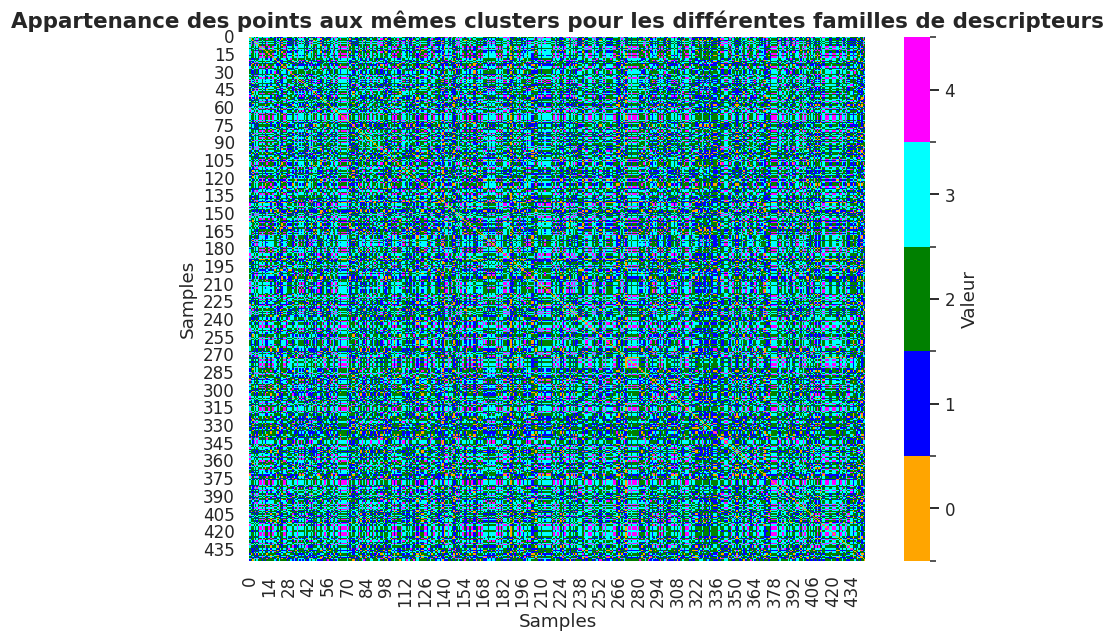

In [37]:
from matplotlib.colors import ListedColormap, BoundaryNorm

colors = ['orange', 'blue', 'green', 'cyan', 'magenta']
cmap = ListedColormap(colors)
boundaries = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
norm = BoundaryNorm(boundaries, ncolors=cmap.N, clip=True)

plt.figure(figsize=(8, 6))
sns.heatmap(total_adjacency_sum, cmap=cmap, norm=norm, cbar=True,
            cbar_kws={'ticks': [0, 1, 2, 3, 4], 'label': 'Valeur'})
plt.title('Appartenance des points aux mêmes clusters pour les différentes familles de descripteurs', fontsize=14, fontweight='bold')
plt.xlabel('Samples', fontsize=12)
plt.ylabel('Samples', fontsize=12)
plt.tight_layout()
plt.savefig("Plots/kmeans/family/appartenance_clusters_familles.png", dpi = 300)
plt.show()

## K-means sur composantes t-SNE

### Calcul des composantes t-SNE

In [38]:
# Calculer les composantes t-SNE pour chaque famille de descripteurs
tsne_results = {}

print("Calcul des composantes t-SNE pour chaque famille...")
print("-" * 70)

for family_name, cols in descriptor_families.items():
    X_family = X_scaled[cols]
    
    # Appliquer t-SNE (2 composantes)
    tsne = TSNE(n_components=2, random_state=random_state, init = 'random', perplexity=30, max_iter=1000, learning_rate= 'auto')
    X_tsne = tsne.fit_transform(X_family)
    
    tsne_results[family_name] = pd.DataFrame(
        X_tsne, 
        columns=['TSNE1', 'TSNE2']
    )
    
    print(f" {family_name}: {X_tsne.shape} ({len(cols)} descripteurs originaux → 2 composantes)")

print("-" * 70)
print(f"\nAperçu des composantes t-SNE pour la première famille:")
first_family = list(tsne_results.keys())[0]
print(tsne_results[first_family].head())

Calcul des composantes t-SNE pour chaque famille...
----------------------------------------------------------------------
 PPI: (444, 2) (5 descripteurs originaux → 2 composantes)
 Pfam: (444, 2) (6 descripteurs originaux → 2 composantes)
 Ks_et_Ka: (444, 2) (7 descripteurs originaux → 2 composantes)
 TE: (444, 2) (7 descripteurs originaux → 2 composantes)
----------------------------------------------------------------------

Aperçu des composantes t-SNE pour la première famille:
       TSNE1      TSNE2
0   1.461847   3.628193
1   2.587034   0.861425
2  11.683982  10.402611
3   1.058245   1.412534
4   2.296066 -10.449755


In [39]:
# Exécuter K-means sur les composantes t-SNE
kmeans_results_tsne = {}

print("Exécution du K-means sur les composantes t-SNE de chaque famille...")
print("-" * 70)

for family_name, tsne_data in tsne_results.items():
    # Dictionnaire pour stocker les métriques pour cette famille
    family_results_tsne = {
        'inertia': [],
        'silhouette': [],
        'davies_bouldin': [],
        'calinski_harabasz': [],
        'models': [],
        'labels': {}
    }
    
    if (family_name== 'Pfam'):
        optimal_k_visua_direct = 5
    elif family_name == 'PPI':
        optimal_k_visua_direct = 5
    elif family_name == 'Ks_et_Ka':
        optimal_k_visua_direct = 2
    else:
        optimal_k_visua_direct = 3

    kmeans = KMeans(n_clusters=optimal_k_visua_direct, n_init=n_init, random_state=random_state, init='k-means++')
    labels = kmeans.fit_predict(tsne_data.values)
    
    # Calculer les métriques
    inertia = kmeans.inertia_
    silhouette = silhouette_score(tsne_data.values, labels) if len(np.unique(labels)) > 1 else np.nan
    davies_bouldin = davies_bouldin_score(tsne_data.values, labels) if len(np.unique(labels)) > 1 else np.nan
    calinski_harabasz = calinski_harabasz_score(tsne_data.values, labels) if len(np.unique(labels)) > 1 else np.nan
    
    family_results_tsne['inertia'].append(inertia)
    family_results_tsne['silhouette'].append(silhouette)
    family_results_tsne['davies_bouldin'].append(davies_bouldin)
    family_results_tsne['calinski_harabasz'].append(calinski_harabasz)
    family_results_tsne['models'].append(kmeans)
    family_results_tsne['labels'] = labels
    
    kmeans_results_tsne[family_name] = family_results_tsne
    print(f" {family_name}: K-means avec t-SNE testé")

print("-" * 70)

Exécution du K-means sur les composantes t-SNE de chaque famille...
----------------------------------------------------------------------
 PPI: K-means avec t-SNE testé
 Pfam: K-means avec t-SNE testé
 Ks_et_Ka: K-means avec t-SNE testé
 TE: K-means avec t-SNE testé
----------------------------------------------------------------------


### Visualisation spatiale des clusters t-SNE

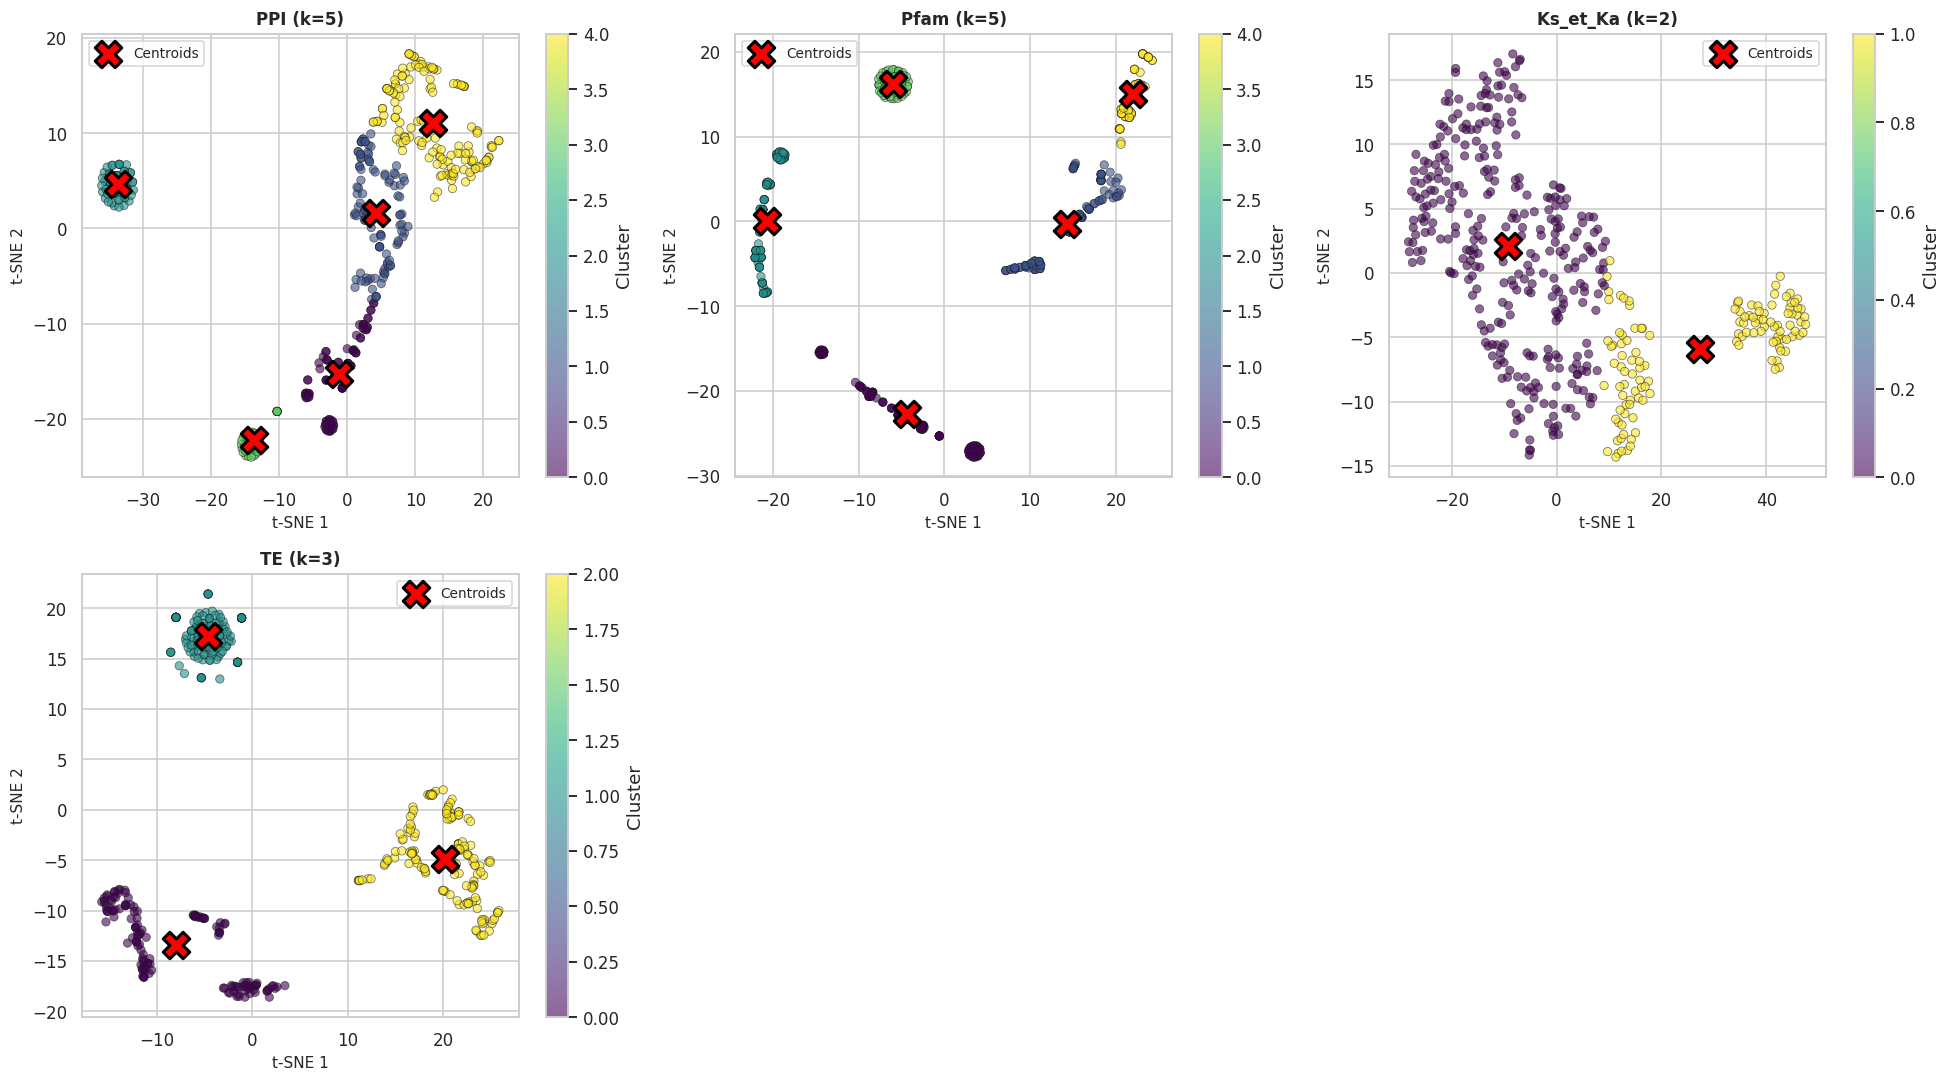

In [40]:
# Visualiser les clusters t-SNE pour k=3
n_families = len(descriptor_families)
n_cols = 3
n_rows = (n_families + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
axes = axes.flatten()

for idx, (family_name, tsne_data) in enumerate(tsne_results.items()):
    if (family_name== 'Pfam'):
        k_family = 5
    elif family_name == 'PPI':
        k_family = 5
    elif family_name == 'Ks_et_Ka':
        k_family = 2
    else :
        k_family = 3
    ax = axes[idx]
    labels = kmeans_results_tsne[family_name]['labels']
    
    scatter = ax.scatter(
        tsne_data['TSNE1'], tsne_data['TSNE2'],
        c=labels, cmap='viridis', s=30, alpha=0.6, edgecolors='k', linewidths=0.5
    )
    
    # Ajouter les centroïdes (utiliser le modèle disponible dans kmeans_results_tsne)
    kmeans_models = kmeans_results_tsne[family_name].get('models', [])
    if len(kmeans_models) > 0:
        kmeans_model = kmeans_models[0]
        centroids = kmeans_model.cluster_centers_
        ax.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=300, 
                   edgecolors='black', linewidths=2, label='Centroids')
    
    ax.set_xlabel(f't-SNE 1', fontsize=10)
    ax.set_ylabel(f't-SNE 2', fontsize=10)
    ax.set_title(f'{family_name} (k={k_family})', fontsize=11, fontweight='bold')
    ax.legend(fontsize=9)
    plt.colorbar(scatter, ax=ax, label='Cluster')

# Masquer les axes inutilisés
for idx in range(n_families, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig('Plots/kmeans/family/tsne_clusters_comparison_ppi_5.png', dpi=300)
plt.show()

### Matrices Z selon les clusters par famille avec composantes t-SNE

In [41]:
# Récupérer la matrice d'adjacence pour les clusters K-means par famille de descripteurs
family_adja_matrix_t_SNE = {}
for family_name, cols in descriptor_families.items():

    # Recalculer les clusters pour cette famille spécifique
    if (family_name== 'Pfam'):
        optimal_k_visua_direct = 5
    elif family_name == 'PPI':
        optimal_k_visua_direct = 5
    elif family_name == 'Ks_et_Ka':
        optimal_k_visua_direct = 2
    else:
        optimal_k_visua_direct = 3

    X_family = X_scaled[cols]
    X_tsne_optimal = tsne.fit_transform(X_family)
    kmeans_optimal_tsne = KMeans(n_clusters=optimal_k_visua_direct, n_init=n_init, random_state=random_state, init='k-means++')
    labels_optimal_tsne = kmeans_optimal_tsne.fit_predict(X_tsne_optimal)
    Z_optimal_tsne = pd.DataFrame(X_tsne_optimal, columns=['TSNE1', 'TSNE2'])
    Z_optimal_tsne['Cluster'] = labels_optimal_tsne
    
    Z_family_binary_tsne = pd.get_dummies(Z_optimal_tsne['Cluster'], prefix='Cluster').astype(int)
    
    adja_matrix_family_t_SNE = Z_family_binary_tsne.values @ Z_family_binary_tsne.values.T
    adja_matrix_family_t_SNE = adja_matrix_family_t_SNE - np.diag(np.diag(adja_matrix_family_t_SNE))  # Soustraire les éléments diagonaux
    family_adja_matrix_t_SNE[family_name] = adja_matrix_family_t_SNE
    
    print(f"\nMatrice d'adjacence pour la famille '{family_name}':")
    print(f"Shape: {adja_matrix_family_t_SNE.shape}")
    print(f"Somme des éléments (nombre de paires dans le même cluster): {adja_matrix_family_t_SNE.sum()/2}")


Matrice d'adjacence pour la famille 'PPI':
Shape: (444, 444)
Somme des éléments (nombre de paires dans le même cluster): 22881.0

Matrice d'adjacence pour la famille 'Pfam':
Shape: (444, 444)
Somme des éléments (nombre de paires dans le même cluster): 20667.0

Matrice d'adjacence pour la famille 'Ks_et_Ka':
Shape: (444, 444)
Somme des éléments (nombre de paires dans le même cluster): 58666.0

Matrice d'adjacence pour la famille 'TE':
Shape: (444, 444)
Somme des éléments (nombre de paires dans le même cluster): 32805.0


In [42]:
# Addition des matrices d'adjacence 2 à 2 et on récupére le nombre de 2 dans la matrice résultante pour chaque paire de familles
family_names = list(family_adja_matrix_t_SNE.keys())
adja_comparison_tsne = pd.DataFrame(index=family_names, columns=family_names)
for i in range(len(family_names)):
    for j in range(i, len(family_names)):
        family_i = family_names[i]
        family_j = family_names[j]
        # Addition des matrices d'adjacence
        adja_tsne_sum = family_adja_matrix_t_SNE[family_i] + family_adja_matrix_t_SNE[family_j]
        
        # Compter le nombre de 2 dans la matrice résultante
        num_twos_tsne = np.sum(adja_tsne_sum == 2) / 2  # Nombre de paires de points dans le même cluster pour les deux familles

        adja_comparison_tsne.loc[family_i, family_j] = num_twos_tsne
        adja_comparison_tsne.loc[family_j, family_i] = num_twos_tsne  # Symétrique

In [43]:
print("\nComparaison des matrices d'adjacence (nombre de paires de points dans le même cluster):")
print(adja_comparison_tsne)


Comparaison des matrices d'adjacence (nombre de paires de points dans le même cluster):
              PPI     Pfam Ks_et_Ka       TE
PPI       22881.0   4937.0  14496.0   7553.0
Pfam       4937.0  20667.0  12585.0   6895.0
Ks_et_Ka  14496.0  12585.0  58666.0  19578.0
TE         7553.0   6895.0  19578.0  32805.0


In [44]:
# On va calculer pour chaque famille de descripteurs le nombre de points qui sont dans le même cluster
tsne_cluster_comparison = pd.DataFrame(index=family_names, columns=[f'Cluster {i}' for i in range(optimal_k_visua_direct)])
for family_name in family_names:
    # Recalculer les clusters pour cette famille spécifique
    if (family_name== 'Pfam'):
        optimal_k_visua_direct = 5
    elif family_name == 'PPI':
        optimal_k_visua_direct = 5
    elif family_name == 'Ks_et_Ka':
        optimal_k_visua_direct = 2
    else:
        optimal_k_visua_direct = 3
    
    X_family = X_scaled[descriptor_families[family_name]]
    X_tsne_optimal = tsne.fit_transform(X_family)
    kmeans_family_tsne = KMeans(n_clusters=optimal_k_visua_direct, n_init=n_init, random_state=random_state, init='k-means++')
    labels_family_tsne = kmeans_family_tsne.fit_predict(X_tsne_optimal)
    
    # Compter le nombre de points dans chaque cluster pour cette famille
    for cluster_id in range(optimal_k_visua_direct):
        num_points_in_cluster_tsne = np.sum(labels_family_tsne == cluster_id)
        tsne_cluster_comparison.loc[family_name, f'Cluster {cluster_id}'] = num_points_in_cluster_tsne
print("\nComparaison entre les familles de descripteurs et les clusters:")
print(tsne_cluster_comparison)


Comparaison entre les familles de descripteurs et les clusters:
         Cluster 0 Cluster 1 Cluster 2  Cluster 3  Cluster 4
PPI             87       108        60       42.0      147.0
Pfam           113       107        98       60.0       66.0
Ks_et_Ka       320       124       NaN        NaN        NaN
TE             142       139       163        NaN        NaN


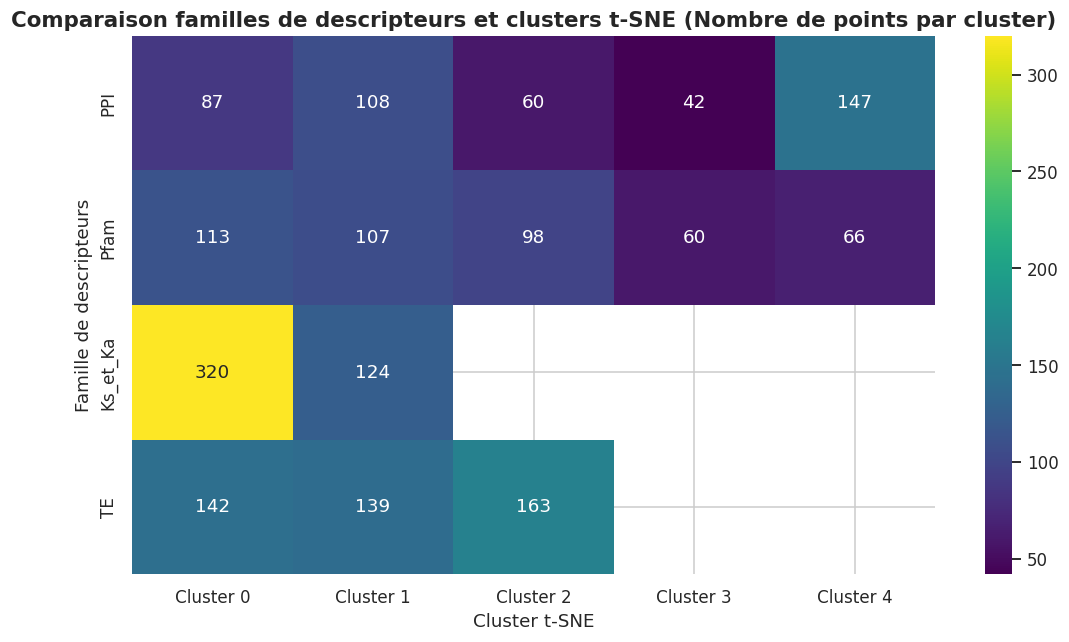

In [45]:
# Faire heatmap de tsne_cluster_comparison
plt.figure(figsize=(10, 6))
sns.heatmap(tsne_cluster_comparison.astype(float), annot=True, fmt=".0f", cmap='viridis', cbar=True)
plt.title('Comparaison familles de descripteurs et clusters t-SNE (Nombre de points par cluster)', fontsize=14, fontweight='bold')
plt.xlabel('Cluster t-SNE', fontsize=12)
plt.ylabel('Famille de descripteurs', fontsize=12)
plt.tight_layout()
# plt.savefig('Plots/kmeans/family/tsne_cluster_comparison_heatmap.png', dpi=300)
plt.show()

In [46]:

tsne_cluster_comparison_sorted = pd.DataFrame(
    index=family_names,
    columns=[f'Cluster {i}' for i in range(5)],
    dtype=float
)

for family_name in family_names:
    if (family_name== 'Pfam'):
        optimal_k_visua_direct = 5
    elif family_name == 'PPI':
        optimal_k_visua_direct = 5
    elif family_name == 'Ks_et_Ka':
        optimal_k_visua_direct = 2
    else:
        optimal_k_visua_direct = 3

    X_family = X_scaled[descriptor_families[family_name]]
    X_tsne_optimal = tsne.fit_transform(X_family)
    kmeans_family_tsne = KMeans(n_clusters=optimal_k_visua_direct, n_init=n_init,
                           random_state=random_state, init='k-means++')
    labels_family_tsne = kmeans_family_tsne.fit_predict(X_tsne_optimal)

    # Compter les points par cluster puis trier — HORS de la boucle cluster_id
    cluster_sizes = [int(np.sum(labels_family_tsne == cluster_id)) for cluster_id in range(optimal_k_visua_direct)]
    points_sorted = sorted(cluster_sizes, reverse=True)

    for rank, val in enumerate(points_sorted):
        tsne_cluster_comparison_sorted.loc[family_name, f'Cluster {rank}'] = val

print("\nComparaison entre les familles de descripteurs et les clusters (points, triés):")
print(tsne_cluster_comparison_sorted)


Comparaison entre les familles de descripteurs et les clusters (points, triés):
          Cluster 0  Cluster 1  Cluster 2  Cluster 3  Cluster 4
PPI           147.0      108.0       87.0       60.0       42.0
Pfam          113.0      107.0       98.0       66.0       60.0
Ks_et_Ka      320.0      124.0        NaN        NaN        NaN
TE            163.0      142.0      139.0        NaN        NaN


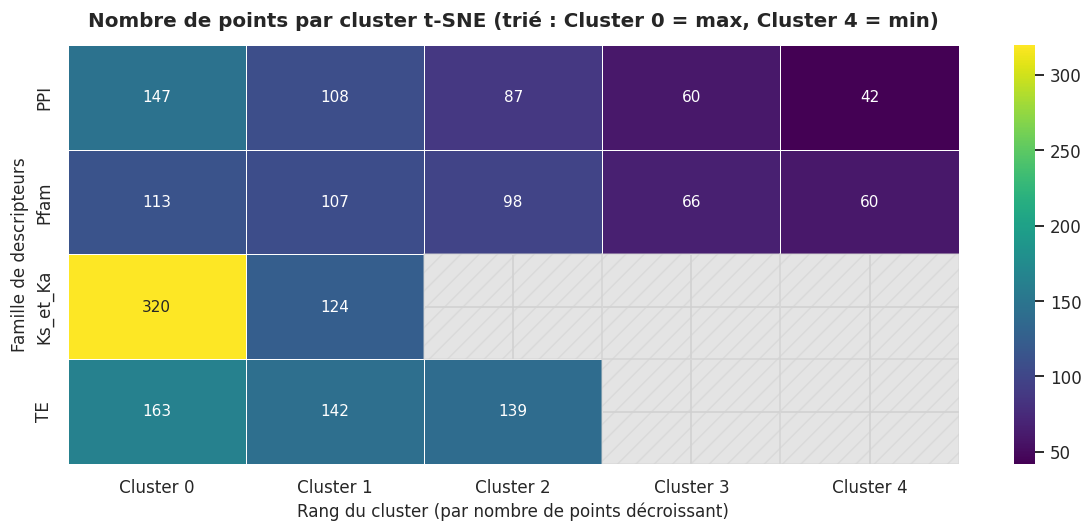

In [47]:
# --- Heatmap ---
fig, ax = plt.subplots(figsize=(11, 5))

mask = tsne_cluster_comparison_sorted.isna()

sns.heatmap(
    tsne_cluster_comparison_sorted.astype(float),
    annot=True,
    fmt=".0f",
    cmap='viridis',
    cbar=True,
    mask=mask,
    linewidths=0.5,
    linecolor='white',
    ax=ax,
    annot_kws={"size": 10}
)

for i in range(tsne_cluster_comparison_sorted.shape[0]):
    for j in range(tsne_cluster_comparison_sorted.shape[1]):
        if mask.iloc[i, j]:
            ax.add_patch(plt.Rectangle(
                (j, i), 1, 1,
                fill=True, color='lightgrey', hatch='//', alpha=0.6
            ))

ax.set_title(
    'Nombre de points par cluster t-SNE (trié : Cluster 0 = max, Cluster 4 = min)',
    fontsize=13, fontweight='bold', pad=12
)
ax.set_xlabel('Rang du cluster (par nombre de points décroissant)', fontsize=11)
ax.set_ylabel('Famille de descripteurs', fontsize=11)
plt.tight_layout()
# plt.savefig('Plots/kmeans/family/cluster_comparison_points_heatmap.png', dpi=300)
plt.show()

In [48]:
# --- Calcul des tailles et ratios redondant/divergent par cluster ---
max_k = max(7, 5, 4, 2, 3)
columns = [f'Cluster {i}' for i in range(max_k)]

tsne_cluster_comparison_sorted = pd.DataFrame(index=family_names, columns=columns, dtype=float)
tsne_ratio_comparison   = pd.DataFrame(index=family_names, columns=columns, dtype=float)

y_train = pd.read_csv("Données/Y_train_clean.csv")
classifications = y_train['Classification'].values  # 0=redondant, 1=divergent

for family_name in family_names:
    if (family_name== 'Pfam'):
        optimal_k_visua_direct = 5
    elif family_name == 'PPI':
        optimal_k_visua_direct = 5
    elif family_name == 'Ks_et_Ka':
        optimal_k_visua_direct = 2
    else:
        optimal_k_visua_direct = 3

    X_family = X_scaled[descriptor_families[family_name]]
    X_tsne_optimal = tsne.fit_transform(X_family)
    kmeans_family_tsne = KMeans(n_clusters=optimal_k_visua_direct, n_init=n_init,
                           random_state=random_state, init='k-means++')
    labels_family_tsne = kmeans_family_tsne.fit_predict(X_tsne_optimal)

    # Calculer taille et ratio pour chaque cluster
    cluster_sizes_tsne  = []
    cluster_ratios_tsne = []
    for cluster_id in range(optimal_k_visua_direct):
        mask_cluster = labels_family_tsne == cluster_id
        n = int(np.sum(mask_cluster))
        n_div = int(np.sum(classifications[mask_cluster] == 1))
        n_red = n - n_div
        ratio = n_red / n_div if n_div > 0 else np.inf  # redondant/divergent
        cluster_sizes_tsne.append(n)
        cluster_ratios_tsne.append(ratio)

    # Trier les deux listes ensemble par taille décroissante
    sorted_pairs = sorted(zip(cluster_sizes_tsne, cluster_ratios_tsne), key=lambda x: x[0], reverse=True)

    for rank, (size, ratio) in enumerate(sorted_pairs):
        tsne_cluster_comparison_sorted.loc[family_name, f'Cluster {rank}'] = size
        tsne_ratio_comparison.loc[family_name,   f'Cluster {rank}'] = ratio

# --- Construction des annotations combinées ---
# Chaque cellule affiche : "N pts\nR:D = x.xx"
annot_matrix_tsne = pd.DataFrame(index=family_names, columns=columns, dtype=object)
nan_mask_tsne = tsne_cluster_comparison_sorted.isna()

for fam in family_names:
    for col in columns:
        if nan_mask_tsne.loc[fam, col]:
            annot_matrix_tsne.loc[fam, col] = ""
        else:
            n     = int(tsne_cluster_comparison_sorted.loc[fam, col])
            ratio_tsne = tsne_ratio_comparison.loc[fam, col]
            ratio_str_tsne = f"{ratio_tsne:.2f}" if not np.isinf(ratio_tsne) else "∞"
            annot_matrix_tsne.loc[fam, col] = f"{n} paires\nR/D={ratio_str_tsne}"

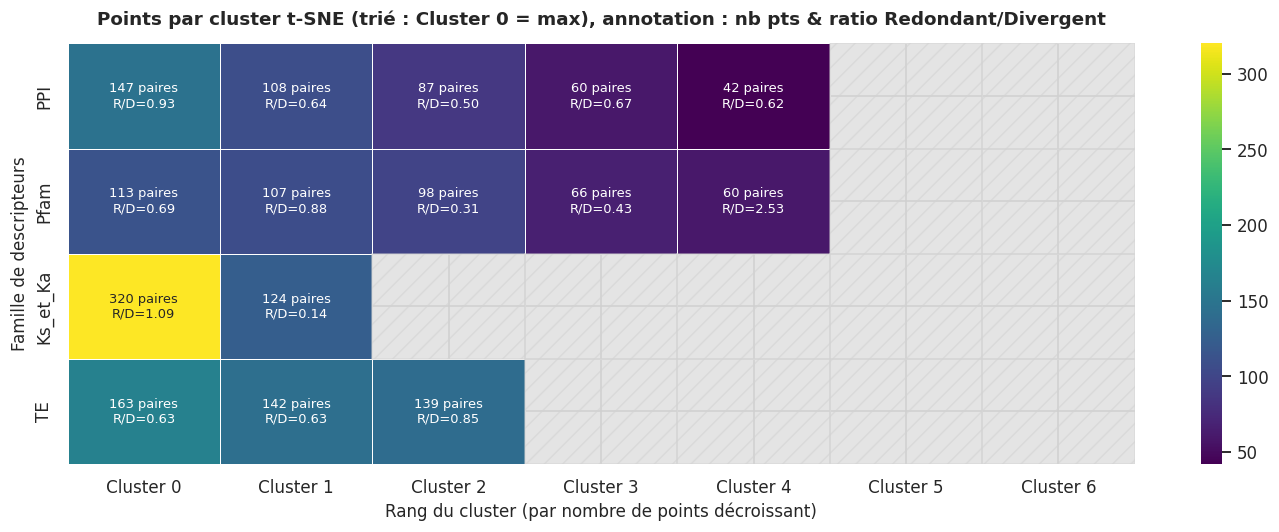

In [49]:
# --- Heatmap ---
fig, ax = plt.subplots(figsize=(13, 5))

data = tsne_cluster_comparison_sorted.astype(float)
annot = annot_matrix_tsne.reindex_like(data)
mask = nan_mask_tsne.reindex_like(data)

sns.heatmap(
    data,
    annot=annot,
    fmt="",
    cmap='viridis',
    cbar=True,
    mask=mask,
    linewidths=0.5,
    linecolor='white',
    ax=ax,
    annot_kws={"size": 8.5}
)

for i in range(tsne_cluster_comparison_sorted.shape[0]):
    for j in range(tsne_cluster_comparison_sorted.shape[1]):
        if nan_mask_tsne.iloc[i, j]:
            ax.add_patch(plt.Rectangle(
                (j, i), 1, 1,
                fill=True, color='lightgrey', hatch='//', alpha=0.6
            ))

ax.set_title(
    'Points par cluster t-SNE (trié : Cluster 0 = max), annotation : nb pts & ratio Redondant/Divergent',
    fontsize=12, fontweight='bold', pad=12
)
ax.set_xlabel('Rang du cluster (par nombre de points décroissant)', fontsize=11)
ax.set_ylabel('Famille de descripteurs', fontsize=11)
plt.tight_layout()
# plt.savefig('Plots/kmeans/family/cluster_comparison_ratio_heatmap.png', dpi=300)
plt.show()

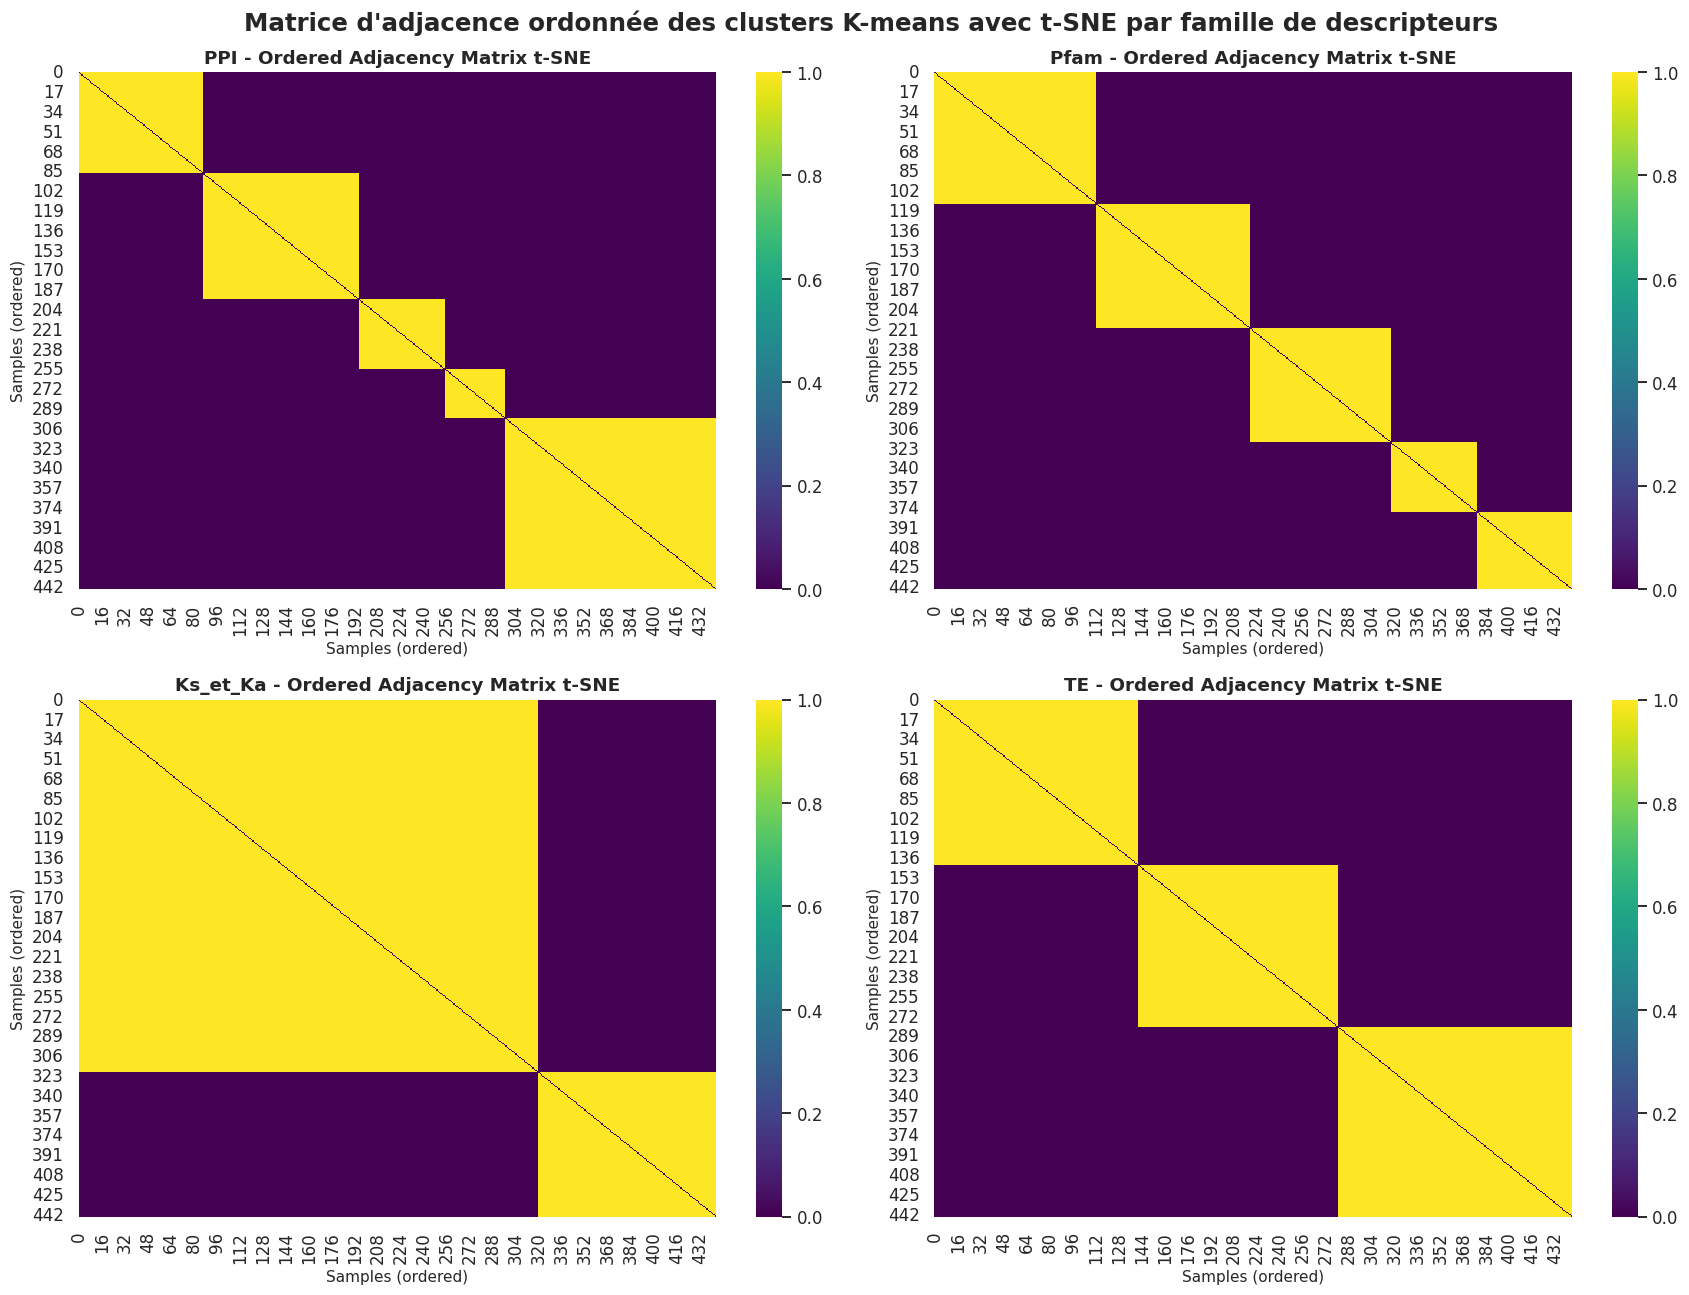

In [50]:
# Ordonnancement matrice d'adjacence t-SNE pour regrouper les points appartenant au même cluster
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Matrice d\'adjacence ordonnée des clusters K-means avec t-SNE par famille de descripteurs', fontsize=16, fontweight='bold')
for idx, (family_name, adja_matrix_t_SNE) in enumerate(family_adja_matrix_t_SNE.items()):
    ax = axes[idx // 2, idx % 2]
    
    # Recalculer les clusters pour cette famille spécifique
    if (family_name== 'Pfam'):
        optimal_k_visua_direct = 5
    elif family_name == 'PPI':
        optimal_k_visua_direct = 5
    elif family_name == 'Ks_et_Ka':
        optimal_k_visua_direct = 2
    else:
        optimal_k_visua_direct = 3
    X_family = X_scaled[descriptor_families[family_name]]
    X_tsne_optimal = tsne.fit_transform(X_family)
    kmeans_family = KMeans(n_clusters=optimal_k_visua_direct, n_init=n_init, random_state=random_state, init='k-means++')
    labels_family = kmeans_family.fit_predict(X_tsne_optimal)
    
    # Ordonner la matrice d'adjacence en regroupant les points du même cluster
    ordered_indices_tsne = np.argsort(labels_family)
    ordered_adjacency_tsne = adja_matrix_t_SNE[ordered_indices_tsne][:, ordered_indices_tsne]
    
    sns.heatmap(ordered_adjacency_tsne, ax=ax, cmap='viridis', cbar=True)
    ax.set_title(f'{family_name} - Ordered Adjacency Matrix t-SNE', fontsize=12, fontweight='bold')
    ax.set_xlabel('Samples (ordered)', fontsize=10)
    ax.set_ylabel('Samples (ordered)', fontsize=10)
plt.tight_layout()
# plt.savefig('Plots/kmeans/family/ordered_adjacency_matrices.png', dpi=300)
plt.show()

In [51]:
# Additionner les matrices d'adjacence de toutes les familles et compter le nombre de 2, 3, 4 dans la matrice résultante
total_adja_tsne_sum = np.zeros_like(list(family_adja_matrix_t_SNE.values())[0])
for adjacency_matrix in family_adja_matrix_t_SNE.values():
    total_adja_tsne_sum += adjacency_matrix

num_zeros_tsne = (np.sum(total_adja_tsne_sum == 0) - 444) / 2
num_ones_tsne = np.sum(total_adja_tsne_sum ==1) / 2 # Nombre de paires de points dans le même cluster pour exactement 1 famille
num_twos_tsne = np.sum(total_adja_tsne_sum == 2) / 2 # Nombre de paires de points dans le même cluster pour exactement 2 familles
num_threes_tsne = np.sum(total_adja_tsne_sum == 3) / 2 # Nombre de paires de points dans le même cluster pour exactement 3 familles
num_fours_tsne = np.sum(total_adja_tsne_sum == 4) / 2 # Nombre de paires de points dans le même cluster pour exactement 4 familles

print(f"Nombre de paires de points dans le même cluster pour exactement 0 famille: {num_zeros_tsne:.0f}")
print(f"\nNombre de paires de points dans le même cluster pour exactement 1 famille: {num_ones_tsne:.0f}")
print(f"\nNombre de paires de points dans le même cluster pour exactement 2 familles: {num_twos_tsne:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 3 familles: {num_threes_tsne:.0f}")
print(f"Nombre de paires de points dans le même cluster pour exactement 4 familles: {num_fours_tsne:.0f}")

Nombre de paires de points dans le même cluster pour exactement 0 famille: 16584

Nombre de paires de points dans le même cluster pour exactement 1 famille: 40233

Nombre de paires de points dans le même cluster pour exactement 2 familles: 30860
Nombre de paires de points dans le même cluster pour exactement 3 familles: 9610
Nombre de paires de points dans le même cluster pour exactement 4 familles: 1059


In [52]:
num_zeros_tsne + num_ones_tsne + num_twos_tsne + num_threes_tsne + num_fours_tsne

np.float64(98346.0)

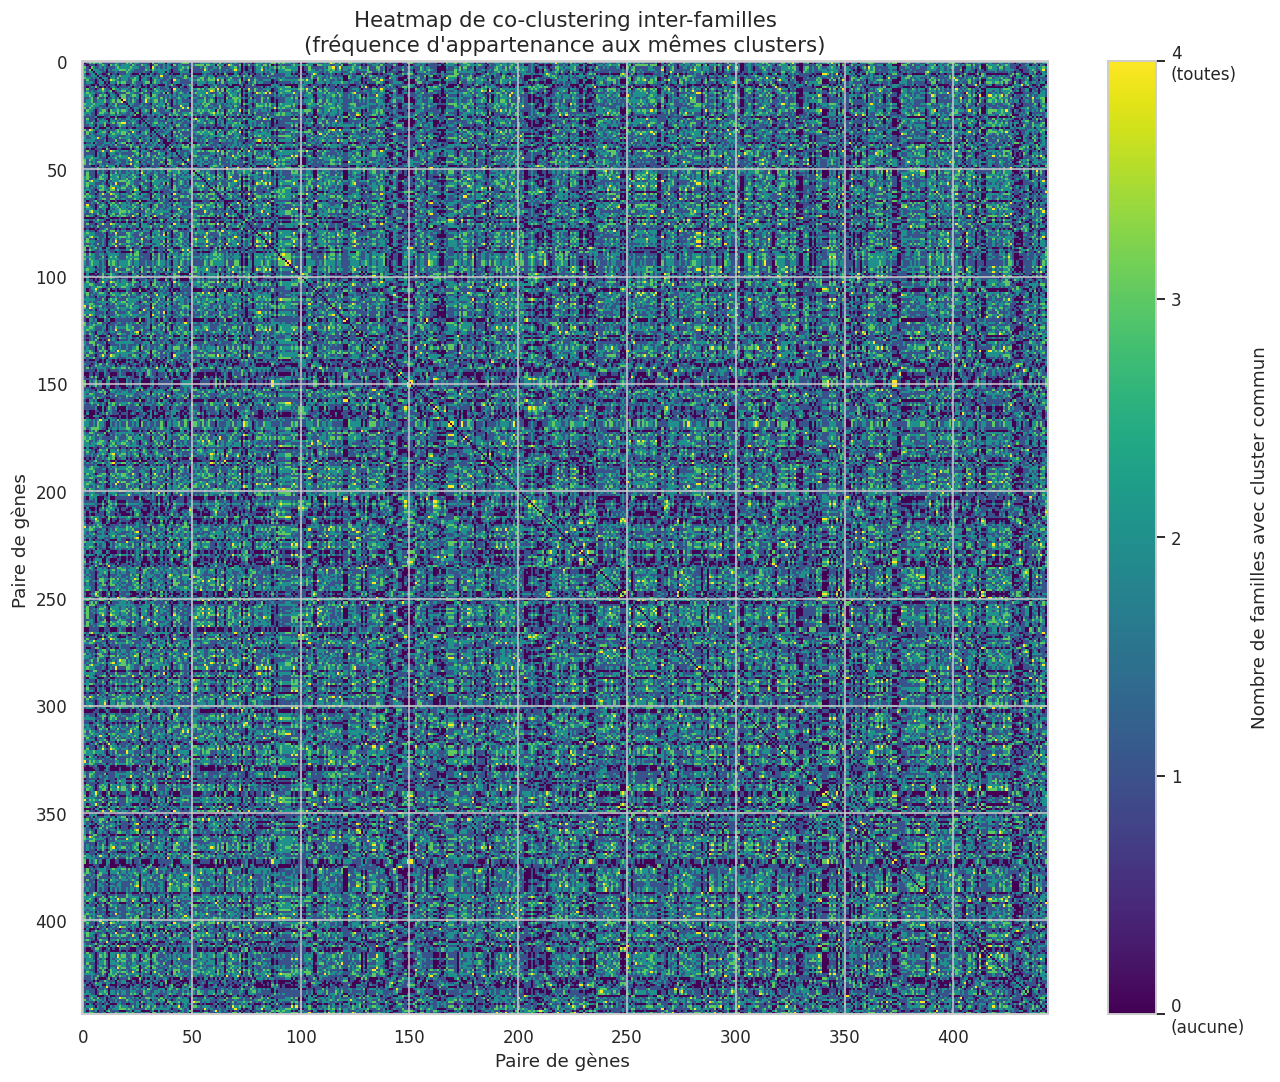


Distribution des valeurs dans la matrice :
  Valeur 0 : 16,584.0 cellules (16.9%)
  Valeur 1 : 40,233.0 cellules (40.9%)
  Valeur 2 : 30,860.0 cellules (31.4%)
  Valeur 3 : 9,610.0 cellules (9.8%)
  Valeur 4 : 1,059.0 cellules (1.1%)


In [53]:
fig, ax = plt.subplots(figsize=(12, 10))

# Heatmap avec colormap violet → jaune
im = ax.imshow(
    total_adja_tsne_sum,
    cmap='viridis',
    vmin=0,
    vmax=4,
    aspect='auto',
    interpolation='nearest'
)

# Colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Nombre de familles avec cluster commun", fontsize=12)
cbar.set_ticks([0, 1, 2, 3, 4])
cbar.set_ticklabels(['0\n(aucune)', '1', '2', '3', '4\n(toutes)'])

# Labels
ax.set_title("Heatmap de co-clustering inter-familles\n(fréquence d'appartenance aux mêmes clusters)", fontsize=14)
ax.set_xlabel("Paire de gènes ", fontsize=12)
ax.set_ylabel("Paire de gènes ", fontsize=12)

plt.tight_layout()
# plt.savefig("Plots/kmeans/family/heatmap_coclustering.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"\nDistribution des valeurs dans la matrice :")
total_count = 0
for v in range(5):
    if v == 0:
        count = np.sum(total_adja_tsne_sum == v) - 444 # Soustraire les éléments diagonaux 
        count = count / 2 # Diviser par 2 pour ne pas compter les paires (i,j) et (j,i)
        pct = 100 * count / ((total_adja_tsne_sum.size - 444 )/2)
    else :
        count = np.sum(total_adja_tsne_sum == v) / 2 # Diviser par 2 pour ne pas compter les paires (i,j) et (j,i)
        pct = 100 * count / ((total_adja_tsne_sum.size  - 444)/ 2)
    print(f"  Valeur {v} : {count:,} cellules ({pct:.1f}%)")
    total_count += count

In [54]:
print(f"  Total : {total_count:,} cellules (100%)")

  Total : 98,346.0 cellules (100%)


In [55]:
# Récupérer les indices (i,j) où la valeur == 4 pour chaque matrice (triangle supérieur uniquement)
rows_tsne, cols_tsne = np.where(np.triu(total_adja_tsne_sum == 4, k=1))
rows_kmeans, cols_kmeans = np.where(np.triu(total_adjacency_sum == 4, k=1))

# Convertir en ensembles de paires pour comparaison
pairs_tsne   = set(zip(rows_tsne, cols_tsne))
pairs_kmeans = set(zip(rows_kmeans, cols_kmeans))

# Comparaison
pairs_common    = pairs_tsne & pairs_kmeans
pairs_only_tsne = pairs_tsne - pairs_kmeans
pairs_only_kmeans = pairs_kmeans - pairs_tsne

print(f"Paires à 4 dans t-SNE           : {len(pairs_tsne)}")
print(f"Paires à 4 dans K-means direct  : {len(pairs_kmeans)}")
print(f"Paires communes aux deux        : {len(pairs_common)}")
print(f"Paires uniquement dans t-SNE    : {len(pairs_only_tsne)}")
print(f"Paires uniquement dans K-means  : {len(pairs_only_kmeans)}")

Paires à 4 dans t-SNE           : 1059
Paires à 4 dans K-means direct  : 7905
Paires communes aux deux        : 418
Paires uniquement dans t-SNE    : 641
Paires uniquement dans K-means  : 7487


In [56]:
# Récupérer les indices (i,j) où la valeur == 1 pour chaque matrice (triangle supérieur uniquement)
rows_tsne_0, cols_tsne_0 = np.where(np.triu(total_adja_tsne_sum == 0, k=1))
rows_kmeans_0, cols_kmeans_0 = np.where(np.triu(total_adjacency_sum == 0, k=1))

# Convertir en ensembles de paires pour comparaison
pairs_tsne_0   = set(zip(rows_tsne_0, cols_tsne_0))
pairs_kmeans_0 = set(zip(rows_kmeans_0, cols_kmeans_0))

# Comparaison
pairs_common_0    = pairs_tsne_0 & pairs_kmeans_0
pairs_only_tsne_0 = pairs_tsne_0 - pairs_kmeans_0
pairs_only_kmeans_0 = pairs_kmeans_0 - pairs_tsne_0

print(f"Paires à 0 dans t-SNE           : {len(pairs_tsne_0)}")
print(f"Paires à 0 dans K-means direct  : {len(pairs_kmeans_0)}")
print(f"Paires communes aux deux        : {len(pairs_common_0)}")
print(f"Paires uniquement dans t-SNE    : {len(pairs_only_tsne_0)}")
print(f"Paires uniquement dans K-means  : {len(pairs_only_kmeans_0)}")

Paires à 0 dans t-SNE           : 16584
Paires à 0 dans K-means direct  : 3784
Paires communes aux deux        : 1905
Paires uniquement dans t-SNE    : 14679
Paires uniquement dans K-means  : 1879


In [57]:
print(total_adja_tsne_sum)

[[0 3 1 ... 1 1 1]
 [3 0 1 ... 2 2 2]
 [1 1 0 ... 1 0 2]
 ...
 [1 2 1 ... 0 1 3]
 [1 2 0 ... 1 0 1]
 [1 2 2 ... 3 1 0]]


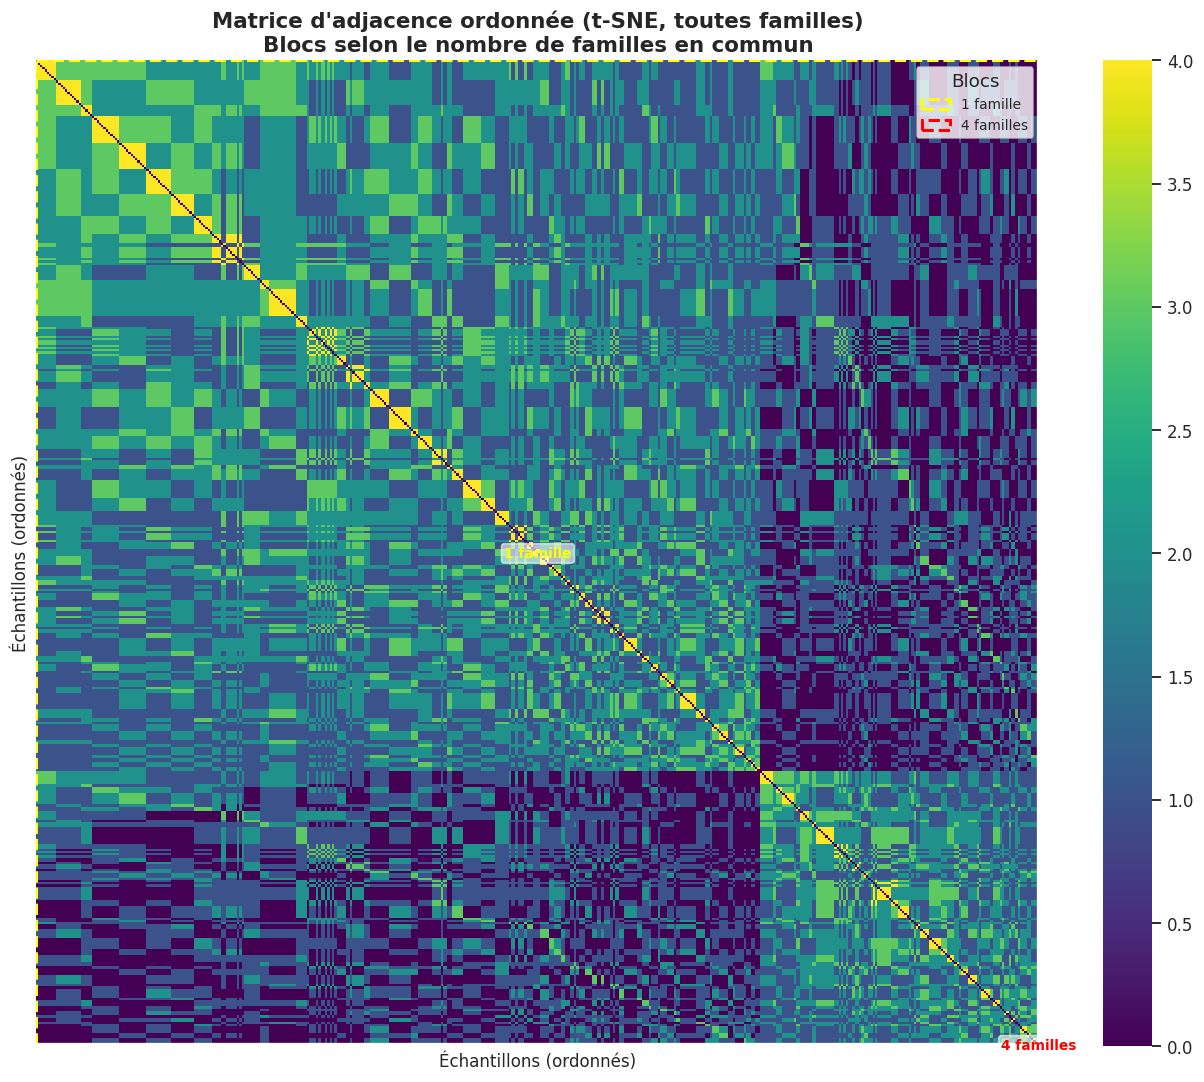

=== Frontières des blocs ===
Bloc '1 famille' : points 0 → 443  (444 points)
Bloc '2 familles' : points 444 → 443  (0 points)
Bloc '3 familles' : points 444 → 442  (-1 points)
Bloc '4 familles' : points 443 → 443  (1 points)

Nombre de paires par catégorie :
  Exactement 1 famille : 40233
  Exactement 2 familles : 30860
  Exactement 3 familles : 9610
  Exactement 4 familles : 1059


In [58]:
from scipy.sparse.csgraph import reverse_cuthill_mckee
from scipy.sparse import csr_matrix

# --- Ordonnancement par valeur de total_adja_tsne_sum ---
# On veut regrouper les points selon le nombre max de familles en commun avec leurs voisins
# Stratégie : trier les points par leur "score" = somme des lignes de total_adja_tsne_sum
# pour que les points très connectés (valeurs 3-4) se retrouvent ensemble

n = total_adja_tsne_sum.shape[0]

# Calcul du score de chaque point : somme pondérée de ses connexions
row_scores = total_adja_tsne_sum.sum(axis=1)
ordered_indices = np.argsort(-row_scores)  # Tri décroissant

# Réordonner la matrice
ordered_matrix = total_adja_tsne_sum[ordered_indices][:, ordered_indices]

# --- Détermination des frontières de blocs ---
# num_ones, num_twos, num_threes, num_fours = nombre de PAIRES avec exactement k familles
# On convertit en nombre de points approximatif pour les frontières visuelles
# Approche : on parcourt la matrice ordonnée et on trouve où passent les valeurs

# Frontières cumulatives (en nombre de points, pas de paires)
# Heuristique : on cherche les "zones" dans la matrice ordonnée
# où la valeur maximale par ligne change de seuil

def find_block_boundaries(ordered_mat, thresholds=[1, 2, 3, 4]):
    """
    Pour chaque ligne i, calcule la valeur max de ses connexions dans la matrice ordonnée.
    Retourne les indices où la valeur max passe sous chaque seuil.
    """
    n = ordered_mat.shape[0]
    boundaries = []
    max_per_row = ordered_mat.max(axis=1)
    
    for thresh in thresholds[:-1]:  # [1, 2, 3]
        # Dernier indice où max_per_row >= thresh+1
        indices_above = np.where(max_per_row >= thresh + 1)[0]
        if len(indices_above) > 0:
            boundaries.append(indices_above[-1] + 1)
        else:
            boundaries.append(0)
    return boundaries  # [i, j, k] = fins des blocs 1-fam, 2-fam, 3-fam

boundaries = find_block_boundaries(ordered_matrix)
block_limits = [0] + boundaries + [n]

# Couleurs des blocs : jaune, vert, bleu, rouge (pour 1, 2, 3, 4 familles)
block_colors = ['yellow', 'green', 'blue', 'red']
block_labels = ['1 famille', '2 familles', '3 familles', '4 familles']

# --- Affichage ---
fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    ordered_matrix,
    ax=ax,
    cmap='viridis',
    cbar=True,
    xticklabels=False,
    yticklabels=False
)

ax.set_title(
    'Matrice d\'adjacence ordonnée (t-SNE, toutes familles)\n'
    'Blocs selon le nombre de familles en commun',
    fontsize=14, fontweight='bold'
)
ax.set_xlabel('Échantillons (ordonnés)', fontsize=11)
ax.set_ylabel('Échantillons (ordonnés)', fontsize=11)

# --- Tracé des rectangles colorés sur les bords ---
for b_idx, (start, end) in enumerate(zip(block_limits[:-1], block_limits[1:])):
    if end <= start:
        continue
    size = end - start
    color = block_colors[b_idx]
    label = block_labels[b_idx]
    
    # Rectangle sur la diagonale (bloc carré)
    rect = plt.Rectangle(
        (start, start), size, size,
        linewidth=2, edgecolor=color, facecolor='none',
        label=label, linestyle='--'
    )
    ax.add_patch(rect)
    
    # Annotation du bloc
    ax.text(
        start + size / 2, start + size / 2,
        label,
        ha='center', va='center',
        fontsize=9, color=color, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.6)
    )

ax.legend(loc='upper right', fontsize=9, title='Blocs')

# Lignes de séparation nettes
for b in boundaries:
    ax.axhline(b, color='white', linewidth=1.5, linestyle='-')
    ax.axvline(b, color='white', linewidth=1.5, linestyle='-')

plt.tight_layout()
# plt.savefig('Plots/kmeans/ordered_adjacency_tsne_sum_blocks.png', dpi=300)
plt.show()

# --- Résumé des blocs ---
print("=== Frontières des blocs ===")
for b_idx, (start, end) in enumerate(zip(block_limits[:-1], block_limits[1:])):
    print(f"Bloc '{block_labels[b_idx]}' : points {start} → {end-1}  ({end-start} points)")
print(f"\nNombre de paires par catégorie :")
print(f"  Exactement 1 famille : {int(num_ones_tsne)}")
print(f"  Exactement 2 familles : {int(num_twos_tsne)}")
print(f"  Exactement 3 familles : {int(num_threes_tsne)}")
print(f"  Exactement 4 familles : {int(num_fours_tsne)}")

In [59]:
total_pairs = len(X_scaled) * (len(X_scaled) - 1) / 2  # Nombre total de paires de points (n*(n-1)/2)
print(f"\nNombre total de paires de points: {total_pairs:.0f}")


Nombre total de paires de points: 98346



Comparaison des matrices d'adjacence (pourcentage de paires de points dans le même cluster):
                PPI       Pfam   Ks_et_Ka         TE  Total_Same_Cluster_Pairs
PPI       59.165599  29.399264  31.804039  28.776971                 89.980274
Pfam      29.399264  52.201411  29.199967  26.271531                 84.870762
Ks_et_Ka  31.804039  29.199967  55.606735  27.686942                 88.690948
TE        28.776971  26.271531  27.686942  49.454985                 82.735444

Comparaison des matrices d'adjacence t-SNE (pourcentage de paires de points dans le même cluster):
                PPI       Pfam   Ks_et_Ka         TE
PPI       23.265817   5.020031  14.739796   7.680028
Pfam       5.020031  21.014581  12.796657   7.010961
Ks_et_Ka  14.739796  12.796657  59.652655  19.907266
TE         7.680028   7.010961  19.907266  33.356720


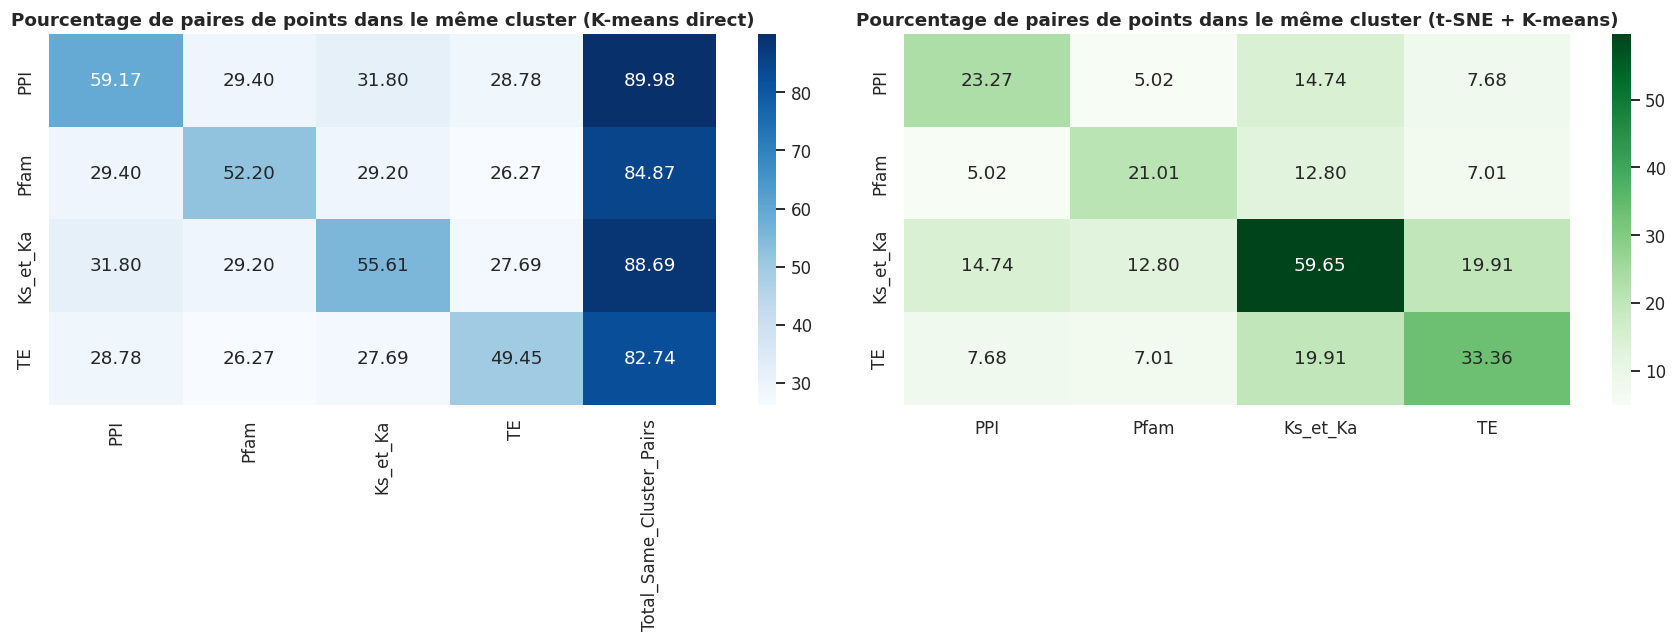

In [60]:
# Récupérer poucentage de points dans même cluster par rapport au nombre total de paires de points
adjacency_comparison_percentage = adjacency_comparison.astype(float) / total_pairs * 100
adja_comparison_tsne_percentage = adja_comparison_tsne.astype(float) / total_pairs * 100
print("\nComparaison des matrices d'adjacence (pourcentage de paires de points dans le même cluster):")
print(adjacency_comparison_percentage)
print("\nComparaison des matrices d'adjacence t-SNE (pourcentage de paires de points dans le même cluster):")
print(adja_comparison_tsne_percentage)
# Visualiser les pourcentages de paires de points dans le même cluster pour les deux approches
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(adjacency_comparison_percentage.astype(float), annot=True, fmt=".2f", cmap='Blues', ax=axes[0])
axes[0].set_title('Pourcentage de paires de points dans le même cluster (K-means direct)', fontsize=12, fontweight='bold')
sns.heatmap(adja_comparison_tsne_percentage.astype(float), annot=True, fmt=".2f", cmap='Greens', ax=axes[1])
axes[1].set_title('Pourcentage de paires de points dans le même cluster (t-SNE + K-means)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('Plots/kmeans/family/adjacency_comparison_percentage.png', dpi=300)
plt.show()

## Export des résultats

In [61]:
# # Exporter les résultats en CSV
# import os

# # Créer un dossier de résultats si nécessaire
# output_dir = 'Résultats_KMeans'
# os.makedirs(output_dir, exist_ok=True)

# # Exporter les métriques pour chaque famille (descripteurs originaux)
# print("Exportation des résultats...")
# print("-" * 70)

# for family_name in kmeans_results_original.keys():
#     metrics_data = {
#         'k': list(k_values),
#         'Inertia_Original': kmeans_results_original[family_name]['inertia'],
#         'Silhouette_Original': kmeans_results_original[family_name]['silhouette'],
#         'DaviesBouldin_Original': kmeans_results_original[family_name]['davies_bouldin'],
#         'CalinskiHarabasz_Original': kmeans_results_original[family_name]['calinski_harabasz'],
#         'Inertia_tSNE': kmeans_results_tsne[family_name]['inertia'],
#         'Silhouette_tSNE': kmeans_results_tsne[family_name]['silhouette'],
#         'DaviesBouldin_tSNE': kmeans_results_tsne[family_name]['davies_bouldin'],
#         'CalinskiHarabasz_tSNE': kmeans_results_tsne[family_name]['calinski_harabasz']
#     }
    
#     metrics_df = pd.DataFrame(metrics_data)
#     filename = f"{output_dir}/kmeans_metrics_{family_name.replace(' ', '_').lower()}.csv"
#     metrics_df.to_csv(filename, index=False)
#     print(f"✓ {filename}")

# # Exporter les composantes t-SNE pour chaque famille
# for family_name, tsne_data in tsne_results.items():
#     filename = f"{output_dir}/tsne_components_{family_name.replace(' ', '_').lower()}.csv"
#     tsne_data.to_csv(filename, index=False)
#     print(f"✓ {filename}")

# # Exporter le résumé des k optimaux
# optimal_k_df.to_csv(f"{output_dir}/optimal_k_summary.csv", index=False)
# print(f"✓ {output_dir}/optimal_k_summary.csv")

# print("-" * 70)
# print(f"\nTous les résultats ont été exportés dans le dossier '{output_dir}'/")